# 00 — Data gathering

This notebook pulls hourly grid data (EIA-930) and weather (Open-Meteo ERA5) for six balancing authorities over 2019–2024, joins them, and freezes the result **unchanged**. It gathers but does not repair: every defect is left in place so that notebook 01 can find it and justify each cleaning decision against the raw table. Nothing after this notebook calls an API.

**Inputs:** EIA-930 API (free key: https://www.eia.gov/opendata/), Open-Meteo ERA5 archive and previous-runs API (no key), CAISO OASIS and MISO market reports.

**Outputs:** `data/processed/panel_raw.parquet`, `manifest.json`, `weather_forecast_holdout.parquet`, `ancillary_prices.parquet`, `docs/data_dictionary.md`; ledger block `nb00` in `results.json`; figures `00_raw_reporting_matrix`, `00_raw_demand_series`, `00_raw_fuel_mix`, `00_raw_map`, `00_weather_points_map`, `00_weather_dataset`, `00_weather_by_year`, `00_duck_curve`.

### 0.1 — Setup

Imports, paths and seed from one `config` module, so zones and cutoffs cannot disagree between notebooks. No output is expected.


In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)


### 0.2 — Where the data comes from

The two sources, their code vocabularies and licences. Most silent errors in this project would be provenance mistakes: a wrong respondent code, the `NG` collision between endpoints, or a timezone mismatch. Check that the respondent codes are the EIA codes (`CISO`, `ERCO`, `SWPP`), not the common names — a wrong code returns HTTP 200 with an empty payload.

#### Source 1 — electricity: EIA-930 Hourly Electric Grid Monitor

| | |
|---|---|
| Publisher | U.S. Energy Information Administration |
| Endpoint | `https://api.eia.gov/v2/electricity/rto/{region-data,fuel-type-data}/data/` |
| Key | Required, free — https://www.eia.gov/opendata/ |
| Granularity | Hourly, **UTC**, US Lower 48 |
| Licence | US government work, **public domain** |

`region-data` gives demand `D`, the day-ahead demand forecast `DF`, net generation `NG` and interchange `TI`. `fuel-type-data` gives generation by fuel in long format and is pivoted to wide. The two are joined on `(respondent, period)`; `NG` (net generation vs natural gas) is renamed before the join so one does not overwrite the other.

#### Source 2 — weather: Open-Meteo ERA5 reanalysis

| | |
|---|---|
| Publisher | Open-Meteo, from ECMWF ERA5 |
| Endpoint | `https://archive-api.open-meteo.com/v1/archive` |
| Key | **None** |
| Granularity | Hourly, requested as **UTC** |
| Licence | **CC-BY-4.0** — attribute Open-Meteo and ECMWF |

`timezone=UTC` is requested explicitly to match EIA-930; mixing local and UTC would shift temperature by hours without any error. Notebook 01 checks the alignment.


In [2]:
# WHAT: print the three code vocabularies and the six weather points.
# WHY:  these are the maps that turn an opaque API payload into named columns. Every
#       one of them has a documented way of going wrong, noted alongside.
from src.sources import RESPONDENTS, REGION_MAP, FUEL_MAP
from src.sources import coord_table

print("=== EIA-930 respondents (the code, NOT the common name) ===")
print(pd.DataFrame({'respondent': list(RESPONDENTS),
                    'balancing authority': list(RESPONDENTS.values())}
                   ).to_string(index=False))
print("\n  A WRONG CODE RETURNS HTTP 200 WITH AN EMPTY PAYLOAD. The loader raises on an")
print("  empty response rather than handing back a frame that joins to nothing.")

print("\n=== region-data series codes ===")
print(pd.DataFrame({'code': list(REGION_MAP), 'column': list(REGION_MAP.values())}
                   ).to_string(index=False))

print("\n=== fuel-type-data codes (confirmed against the API's facet metadata) ===")
print(pd.DataFrame({'code': list(FUEL_MAP), 'column': list(FUEL_MAP.values())}
                   ).to_string(index=False))
print("\n  `NG` MEANS TWO DIFFERENT THINGS: net generation in region-data, natural gas")
print("  in fuel-type-data. Both are renamed BEFORE the join, or one overwrites the other.")

print("\n=== weather points — one per BA, with the reason for each ===")
print(coord_table().to_string(index=False))
print("\n  ONE point per BA is a stated limitation, not an oversight. MISO is the weakest")
print("  case: a single point in Minneapolis for a footprint reaching Louisiana.")

=== EIA-930 respondents (the code, NOT the common name) ===
respondent             balancing authority
      CISO          California ISO (CAISO)
      ERCO                           ERCOT
      MISO                Midcontinent ISO
      SWPP      Southwest Power Pool (SPP)
      BPAT Bonneville Power Administration
      NYIS            New York ISO (NYISO)

  A WRONG CODE RETURNS HTTP 200 WITH AN EMPTY PAYLOAD. The loader raises on an
  empty response rather than handing back a frame that joins to nothing.

=== region-data series codes ===
code            column
   D            demand
  DF   demand_forecast
  NG    net_generation
  TI total_interchange

=== fuel-type-data codes (confirmed against the API's facet metadata) ===
code          column
 SUN           solar
 WND            wind
 WAT           hydro
 NUC         nuclear
  NG             gas
 COL            coal
 OIL             oil
 OTH           other
 GEO      geothermal
 UNK    unknown_fuel
 BAT         battery
  PS  pump

### 0.3 — Pull the raw panel

Pull EIA-930 for six respondents and Open-Meteo for six points, join on `(zone, timestamp)`, and write `panel_raw.parquet` without changes. Everything is cached under `data/raw/`, so a re-run is free. The only check here is weather coverage: `load_raw_panel` raises if `temp` is under 90% populated.

Check that `source=` is not `synthetic`. Expect ~315,600 rows: six zones × 52,608 hours.


In [3]:
# WHAT: gather both sources and freeze the raw join.
# WHY:  load_raw_panel does NOT clean. No dedupe, no regular grid, no interpolation,
#       no clipping, no derived columns, nothing dropped. Notebook 01 owns all of that.
from src.data import load_raw_panel

raw = load_raw_panel(force=True)
manifest = json.loads(cfg.MANIFEST.read_text())

print(f"\nsource   : {manifest['data_source']}")
print(f"artefact : {manifest['artefact']}")
print(f"sha256   : {manifest['panel_sha256_16']}")
print(f"built at : {manifest['built_at']}")
raw.head()

Building the panel from the cached EIA-930 and Open-Meteo pulls in data/raw/ (no EIA key needed for a rebuild).

  CISO: cached (eia930_CISO_2019_2024.parquet)
  ERCO: cached (eia930_ERCO_2019_2024.parquet)
  MISO: cached (eia930_MISO_2019_2024.parquet)
  SWPP: cached (eia930_SWPP_2019_2024.parquet)
  BPAT: cached (eia930_BPAT_2019_2024.parquet)
  NYIS: cached (eia930_NYIS_2019_2024.parquet)
  CISO: weather cached (weather_CISO_2019_2024_v2.parquet)


  ERCO: weather cached (weather_ERCO_2019_2024_v2.parquet)


  MISO: weather cached (weather_MISO_2019_2024_v2.parquet)


  SWPP: weather cached (weather_SWPP_2019_2024_v2.parquet)


  BPAT: weather cached (weather_BPAT_2019_2024_v2.parquet)


  NYIS: weather cached (weather_NYIS_2019_2024_v2.parquet)



panel_raw.parquet written: 315,648 rows x 32 columns
  zones   : ['BPAT', 'CISO', 'ERCO', 'MISO', 'NYIS', 'SWPP']
  span    : 2019-01-01 00:00:00 -> 2024-12-31 23:00:00
  source  : eia930+open-meteo
  sha256  : 88e12050c751419c
  NOT cleaned. Defects are found and repaired in notebook 01 (EDA).

source   : eia930+open-meteo
artefact : panel_raw.parquet
sha256   : 88e12050c751419c
built at : 2026-10-04T15:40:53+00:00


,timestamp,demand,demand_forecast,net_generation,total_interchange,coal,gas,nuclear,oil,other,solar,hydro,wind,zone,battery,unknown_storage,solar_battery,temp,humidity,wind_speed,cloud_cover,ghi,dni_horiz,dhi,wind_speed_100m,wind_gust,apparent_temp,dew_point,snowfall,snow_depth,precipitation,pressure
0,2019-01-01,7026.0,7263.0,10660.0,8921.0,NaN,1447.0,1168.0,NaN,207.0,2.0,7761.0,17.0,BPAT,NaN,NaN,NaN,5.1,71,9.9,1,106.0,68.0,38.0,20.9,20.5,1.5,0.3,0.00,0.00,0.0,1027.6
1,2019-01-01,23216.0,22491.0,15042.0,-6138.0,9.0,6574.0,2273.0,88.0,-22.0,1222.0,2403.0,2497.0,CISO,NaN,NaN,NaN,15.3,49,9.2,1,203.0,148.0,55.0,12.2,27.7,12.6,4.5,0.00,0.00,0.0,999.9
2,2019-01-01,38397.0,37423.0,38197.0,-200.0,9400.0,19491.0,3915.0,NaN,26.0,161.0,189.0,5020.0,ERCO,NaN,NaN,NaN,9.8,73,11.9,80,10.0,3.0,7.0,13.4,13.7,6.8,5.2,0.00,0.00,0.0,997.2
3,2019-01-01,74304.0,81595.0,70466.0,-5676.0,30814.0,11458.0,11970.0,NaN,1012.0,0.0,1231.0,13981.0,MISO,NaN,NaN,NaN,-6.8,82,24.1,99,0.0,0.0,0.0,39.6,47.2,-13.5,-9.4,0.07,0.08,0.1,986.2
4,2019-01-01,19586.0,19468.0,16454.0,-3132.0,0.0,5200.0,5333.0,0.0,1114.0,0.0,3854.0,950.0,NYIS,NaN,NaN,NaN,5.6,95,17.1,100,0.0,0.0,0.0,32.1,37.1,1.8,4.8,0.00,0.00,4.1,1017.1


### 0.4 — The raw matrix

Shape, dtypes, memory and rows per zone. EIA returns values as strings, so `float64` here shows the numeric cast happened (`humidity` and `cloud_cover` arrive as `int64`). Every zone should cover its 52,608 hours. Differences in non-null counts are left for notebook 01's missingness analysis.


In [4]:
# WHAT: the inventory of what was gathered. Description only -- nothing is judged
#       or repaired here.
print(f"shape   : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"memory  : {raw.memory_usage(deep=True).sum() / 1024**2:,.1f} MB in memory")
print(f"on disk : {cfg.PANEL_RAW.stat().st_size / 1024**2:,.1f} MB "
      f"({cfg.PANEL_RAW.name}, parquet)")
print(f"span    : {raw[cfg.TIME_COL].min()} -> {raw[cfg.TIME_COL].max()} (UTC)")
print(f"zones   : {sorted(raw[cfg.GROUP_COL].unique())}")

print("\n--- dtypes (every EIA measurement must be float64: the string cast happened) ---")
print(raw.dtypes.to_string())

# What each respondent actually returned, against what the window could contain.
hours_in_window = int(
    (pd.Timestamp(cfg.END.replace('T', ' ') + ':00:00')
     - pd.Timestamp(cfg.START.replace('T', ' ') + ':00:00')).total_seconds() // 3600) + 1
per_zone = (raw.groupby(cfg.GROUP_COL)[cfg.TIME_COL]
              .agg(rows='count', first='min', last='max')
              .assign(hours_in_window=hours_in_window)
              .assign(pct_of_window=lambda d: (100 * d['rows'] / hours_in_window).round(2)))
print(f"\n--- rows returned per zone (window contains {hours_in_window:,} hours) ---")
display(per_zone)

# Non-null counts per column. This is INVENTORY, not analysis -- notebook 01 asks whether
# the missingness is random or systematic, and decides what to do about it.
census = pd.DataFrame({
    'non_null': raw.notna().sum(),
    'null': raw.isna().sum(),
}).assign(pct_null=lambda d: (100 * d['null'] / len(raw)).round(3))
print("\n--- non-null census by column (inventory only; analysed in notebook 01) ---")
display(census.sort_values('null', ascending=False))

shape   : 315,648 rows x 32 columns
memory  : 90.6 MB in memory
on disk : 12.5 MB (panel_raw.parquet, parquet)
span    : 2019-01-01 00:00:00 -> 2024-12-31 23:00:00 (UTC)
zones   : ['BPAT', 'CISO', 'ERCO', 'MISO', 'NYIS', 'SWPP']

--- dtypes (every EIA measurement must be float64: the string cast happened) ---
timestamp            datetime64[ns]
demand                      float64
demand_forecast             float64
net_generation              float64
total_interchange           float64
coal                        float64
gas                         float64
nuclear                     float64
oil                         float64
other                       float64
solar                       float64
hydro                       float64
wind                        float64
zone                         object
battery                     float64
unknown_storage             float64
solar_battery               float64
temp                        float64
humidity                      int64
wind_

,rows,first,last,hours_in_window,pct_of_window
zone,,,,,
BPAT,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0
CISO,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0
ERCO,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0
MISO,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0
NYIS,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0
SWPP,52608,2019-01-01,2024-12-31 23:00:00,52608,100.0



--- non-null census by column (inventory only; analysed in notebook 01) ---


,non_null,null,pct_null
unknown_storage,1337,314311,99.576
battery,1337,314311,99.576
solar_battery,1407,314241,99.554
oil,157740,157908,50.027
coal,262887,52761,16.715
hydro,307575,8073,2.558
other,307589,8059,2.553
total_interchange,315074,574,0.182
demand_forecast,315383,265,0.084
solar,315420,228,0.072


### 0.5 — What the raw data looks like

Three descriptive figures: which series each respondent reports, the raw demand series, and the generation mix. They confirm that six different power systems came back for six continuous years, and check the premise that the zones differ in renewable mix. Nothing is cleaned; defects are named and passed to notebook 01.


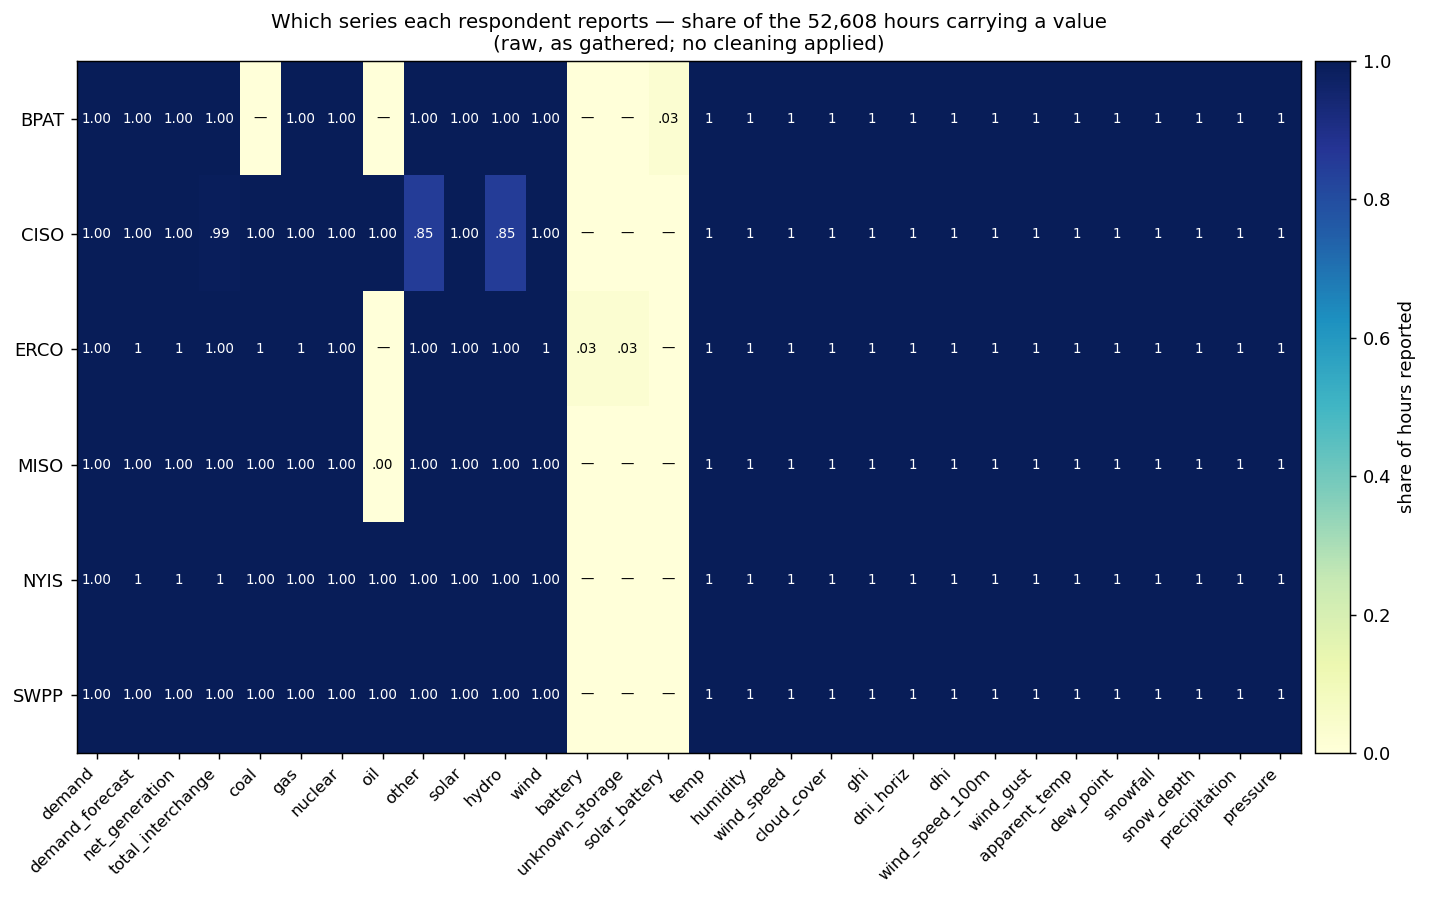

columns in the panel that no respondent reports at all:
   none

columns only SOME respondents report:
   coal               reported by ['CISO', 'ERCO', 'MISO', 'NYIS', 'SWPP']
   oil                reported by ['CISO', 'MISO', 'NYIS', 'SWPP']
   battery            reported by ['ERCO']
   unknown_storage    reported by ['ERCO']
   solar_battery      reported by ['BPAT']


In [5]:
# FIGURE 1 -- which series each respondent actually reports.
# WHAT: share of the 52,608 hours for which each (zone, column) pair carries a value.
# WHY:  this is a GATHERING inventory, not a missingness analysis. The question it
#       answers is "did each respondent serve this series at all", which is a fact
#       about the source. Whether a gap is random or systematic, and what to do about
#       it, is notebook 01's question and is not asked here.
measure_cols = [c for c in raw.columns if c not in (cfg.TIME_COL, cfg.GROUP_COL)]
reported = (raw.groupby(cfg.GROUP_COL)[measure_cols]
              .apply(lambda g: g.notna().mean())
              .reindex(sorted(raw[cfg.GROUP_COL].unique())))

fig, ax = plt.subplots(figsize=(12.0, 7.0))
im = ax.imshow(reported.values, aspect='auto', cmap='YlGnBu', vmin=0, vmax=1)

ax.set_xticks(range(len(measure_cols)))
ax.set_xticklabels(measure_cols, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(reported.index)))
ax.set_yticklabels(reported.index, fontsize=10)
ax.set_title('Which series each respondent reports — share of the 52,608 hours '
             'carrying a value\n(raw, as gathered; no cleaning applied)', fontsize=11)

# annotate every cell, because the interesting values are 0 and 1 and the eye
# cannot tell 0.98 from 1.00 on a colour ramp
for i in range(reported.shape[0]):
    for j in range(reported.shape[1]):
        v = reported.values[i, j]
        ax.text(j, i, '—' if v == 0 else f'{v:.2f}'.lstrip('0') if v < 1 else '1',
                ha='center', va='center', fontsize=7.5,
                color='white' if v > 0.55 else 'black')

fig.colorbar(im, ax=ax, label='share of hours reported', pad=0.01)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_raw_reporting_matrix.png', bbox_inches='tight')
plt.show()

# FUEL_MAP codes the API never returned for these six respondents (geothermal,
# unknown_fuel, pumped_storage, other_storage, wind_battery) never become columns,
# so this check can only cover the columns that ARE in the panel.
print("columns in the panel that no respondent reports at all:")
print("  ", [c for c in measure_cols if reported[c].sum() == 0] or "none")
print("\ncolumns only SOME respondents report:")
partial = [c for c in measure_cols if 0 < (reported[c] > 0).sum() < len(reported)]
for c in partial:
    who = list(reported.index[reported[c] > 0])
    print(f"   {c:18s} reported by {who}")

**What this shows:** Figure 1 (`00_raw_reporting_matrix`): the share of each zone's 52,608 hours for which each column has a value; `—` means never reported.

**What I see:** Most cells are 1.00. BPAT reports no `coal` or `oil` and ERCO no `oil`. CISO's `other` and `hydro` sit at 0.85 and `total_interchange` at 0.99. MISO's `oil` shows 0.00 (present in very few hours). `battery` and `unknown_storage` (ERCO) and `solar_battery` (BPAT) are at 0.03 because EIA began publishing them recently. All fifteen weather columns are 1.00.

**What it means:** "Missing" means different things here. BPAT has no coal fleet, so NaN is correct. CISO's two columns at the same 0.85 look like one reporting period rather than scattered gaps. The full weather row means the ERA5 join lost no rows.

**What I do:** Nothing here. Notebook 01 checks whether CISO's 15% is one period, what MISO's `oil` records are, and imputes per zone only.


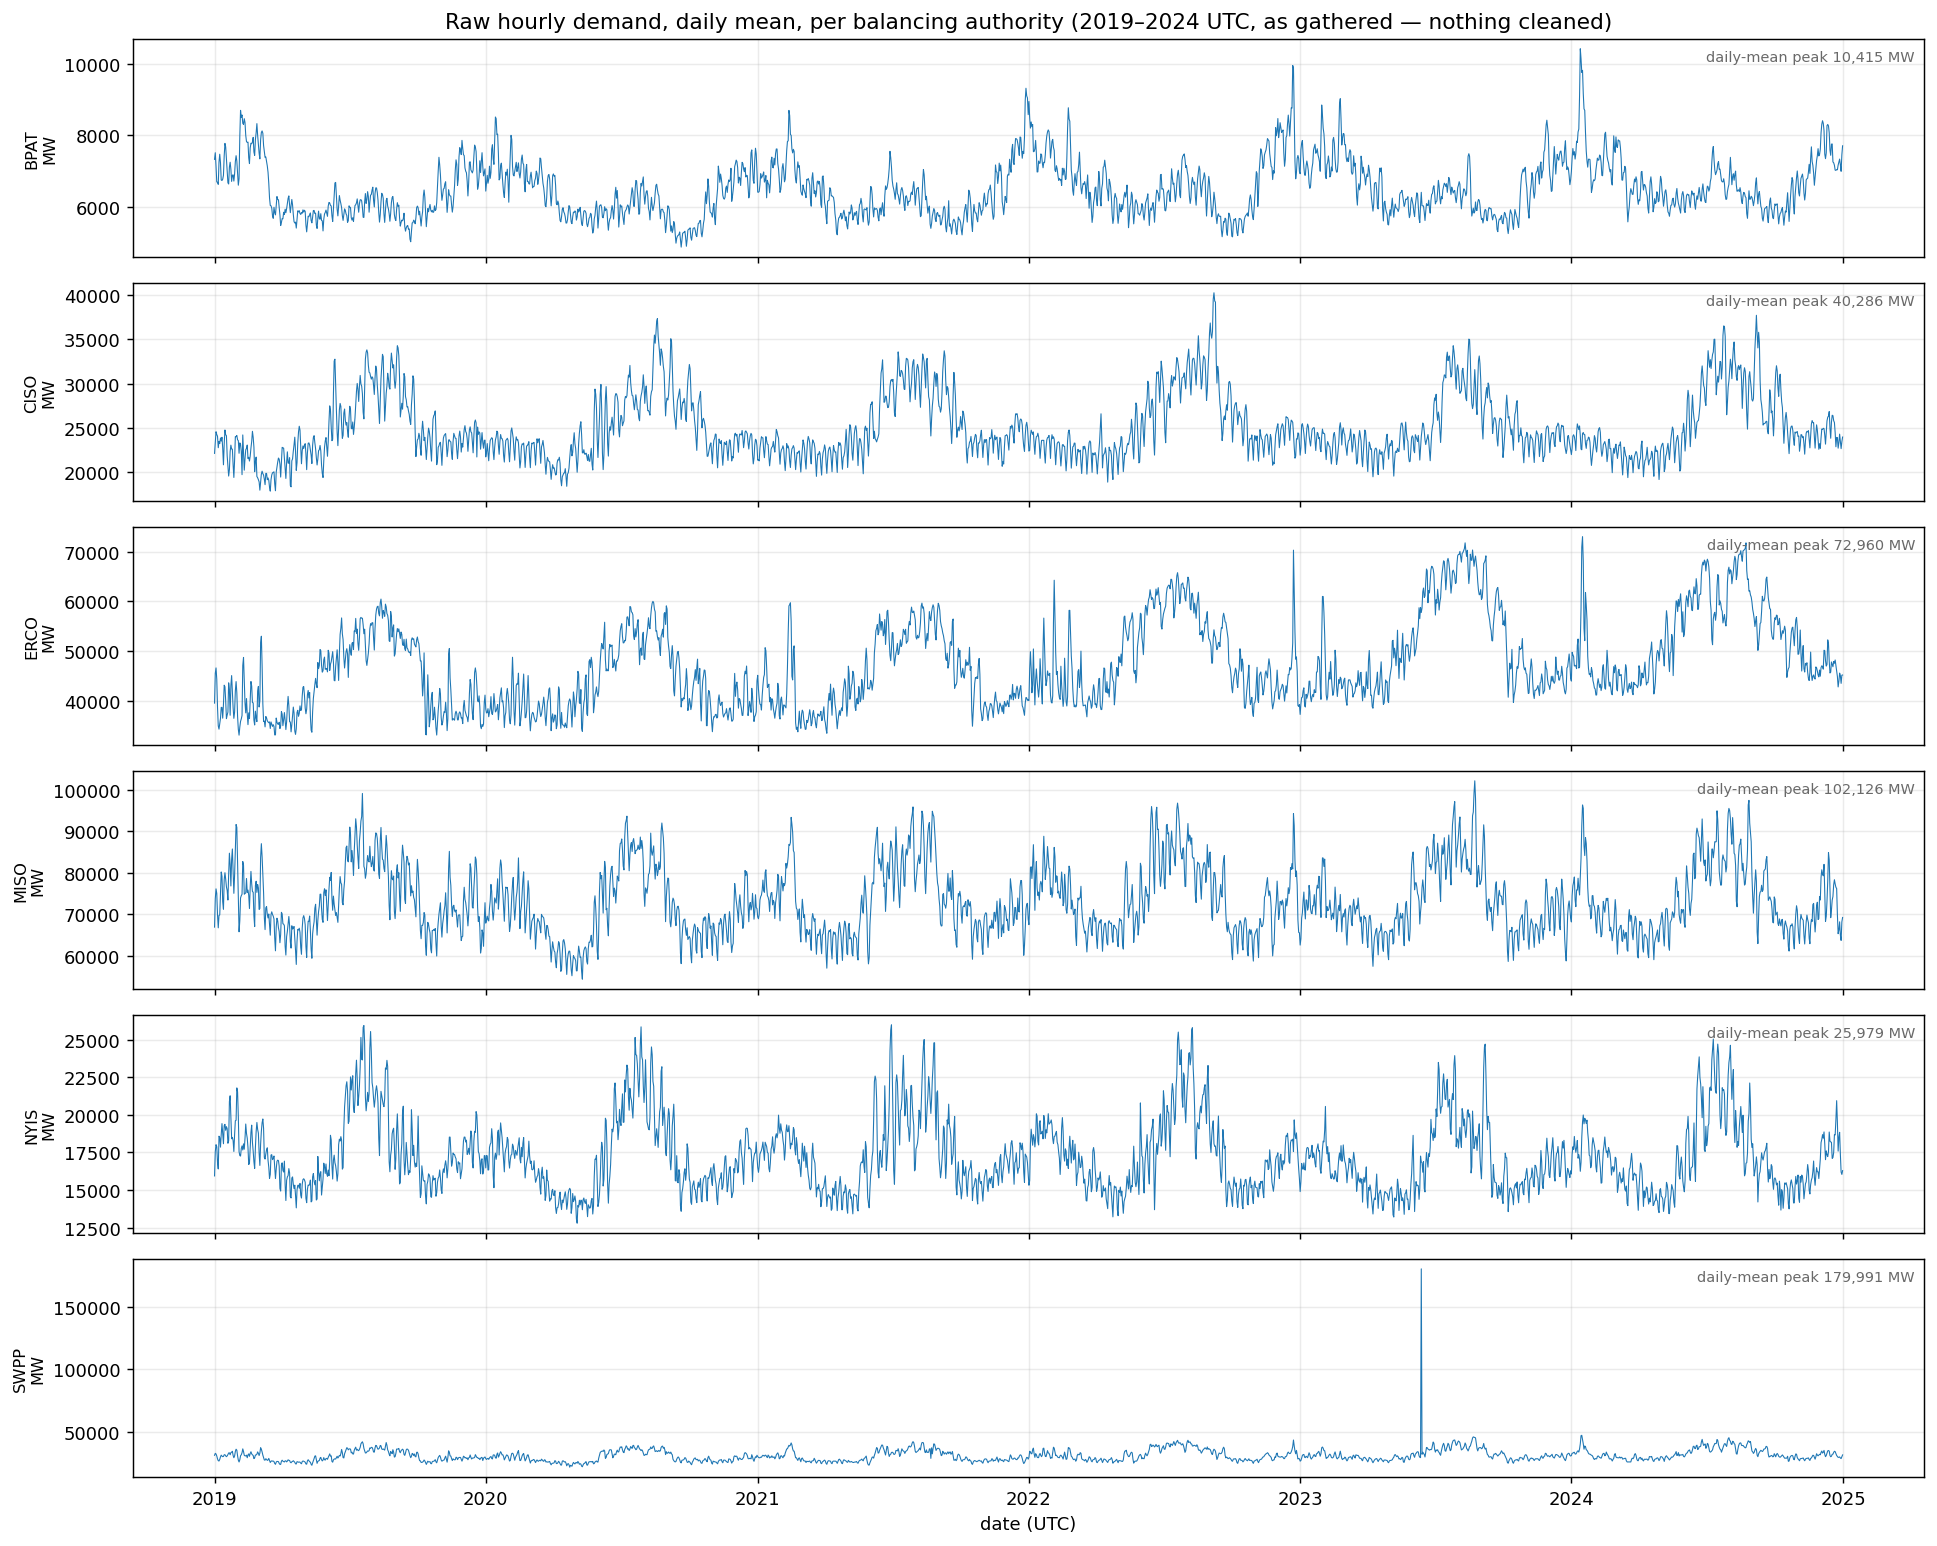

--- daily-mean demand per zone (MW), raw ---
zone     BPAT     CISO     ERCO      MISO     NYIS      SWPP
min    4869.0  17844.0  33172.0   54394.0  12790.0   22071.0
mean   6494.0  25038.0  47490.0   73309.0  17271.0   31474.0
max   10415.0  40286.0  72960.0  102126.0  25979.0  179991.0


In [6]:
# FIGURE 2 -- the raw demand series, one panel per respondent, as gathered.
# WHAT: daily mean of hourly `demand` for each zone across the full window.
# WHY:  the single most direct evidence that six distinct, continuous power systems
#       came back. Daily means only to make six years legible on one page -- the
#       underlying data is hourly and untouched.
# NOTE: each panel keeps its OWN y-axis. A shared axis would compress BPAT (peak
#       ~12 GW) into a flat line against MISO (~122 GW) and hide everything.
daily = (raw.set_index(cfg.TIME_COL)
            .groupby([cfg.GROUP_COL, pd.Grouper(freq='D')])['demand']
            .mean().unstack(0))

zones = sorted(raw[cfg.GROUP_COL].unique())
fig, axes = plt.subplots(len(zones), 1, figsize=(15, 12), sharex=True)
for ax, z in zip(axes, zones):
    ax.plot(daily.index, daily[z], lw=0.6, color='tab:blue')
    ax.set_ylabel(f'{z}\nMW', fontsize=9)
    ax.grid(alpha=.25)
    peak = daily[z].max()
    ax.annotate(f'daily-mean peak {peak:,.0f} MW', xy=(0.995, 0.90),
                xycoords='axes fraction', ha='right', fontsize=8, color='dimgray')
axes[0].set_title('Raw hourly demand, daily mean, per balancing authority '
                  '(2019–2024 UTC, as gathered — nothing cleaned)', fontsize=12)
axes[-1].set_xlabel('date (UTC)')
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_raw_demand_series.png', bbox_inches='tight')
plt.show()

print("--- daily-mean demand per zone (MW), raw ---")
print(daily.describe().loc[['min', 'mean', 'max']].round(0).to_string())

**What this shows:** Figure 2 (`00_raw_demand_series`): daily mean of raw hourly `demand` per zone, each panel on its own y-axis.

**What I see:** Five panels are continuous and seasonal: BPAT mean 6,494 MW, CISO 25,038, ERCO 47,490, MISO 73,309, NYIS 17,271. ERCO's seasonal troughs rise across the window. SWPP is dominated by one spike reaching a daily mean of 179,991 MW in mid-2023, against a SWPP mean of 31,474 MW.

**What it means:** The gather worked: six distinct systems in the expected order of size (MISO > ERCO > SWPP > CISO > NYIS > BPAT), each continuous. The SWPP spike is a corrupt record; the underlying hourly value is 3,621,097 MW (§0.7). It is larger than MISO's highest daily mean, so it cannot be real.

**What I do:** Leave it in the raw table and pass it to notebook 01 as the first defect to resolve, since one such hour would distort every SWPP summary statistic.


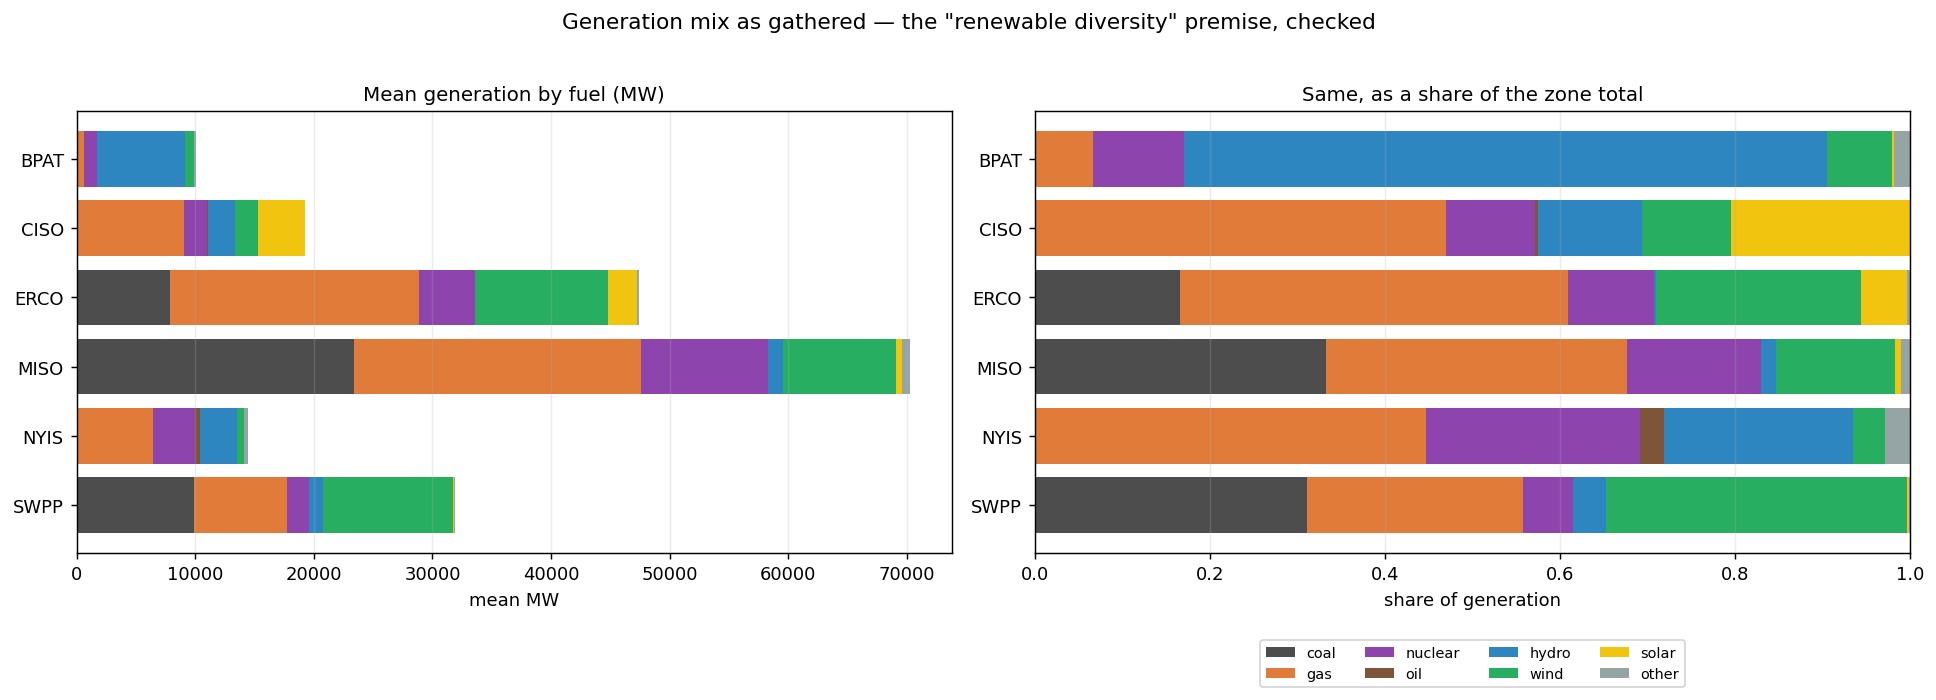

--- mean generation share by fuel, per zone (raw) ---
      coal   gas  nuclear  oil  hydro  wind  solar  other
zone                                                     
BPAT   0.0   6.7     10.4  0.0   73.4   7.5    0.2    1.8
CISO   0.0  46.9     10.2  0.3   11.9  10.2   20.4   -0.0
ERCO  16.7  44.3      9.8  0.0    0.1  23.5    5.2    0.3
MISO  33.3  34.4     15.3  0.0    1.7  13.5    0.8    1.0
NYIS   0.0  44.7     24.4  2.8   21.5   3.7    0.0    2.8
SWPP  31.1  24.6      5.7  0.1    3.7  34.4    0.2    0.1

--- wind and solar share, the two the project is actually about ---
      wind  solar  combined
zone                       
SWPP  34.4    0.2      34.6
CISO  10.2   20.4      30.6
ERCO  23.5    5.2      28.7
MISO  13.5    0.8      14.3
BPAT   7.5    0.2       7.7
NYIS   3.7    0.0       3.7


In [7]:
# FIGURE 3 -- the generation mix each respondent actually serves.
# WHAT: left, mean MW by fuel per zone (absolute scale); right, the same as a share
#       of that zone's mean total generation.
# WHY:  the project selected these six zones FOR their renewable diversity. This is
#       where that premise is checked against the data rather than asserted.
# CAVEAT, stated because it changes how the bars read: a fuel a respondent does not
#       report is drawn as zero. "Does not report" and "reports zero" are NOT the
#       same claim -- figure 1 is what distinguishes them, and this chart must be
#       read next to it.
FUELS = ['coal', 'gas', 'nuclear', 'oil', 'hydro', 'wind', 'solar', 'other']
# A fuel a zone reports in under 1% of its hours (MISO oil: 24 hours in six years) is
# treated as not reported: its mean over those few hours is not a six-year mean.
_rare = raw.groupby(cfg.GROUP_COL)[FUELS].apply(lambda g: g.notna().mean() < 0.01)
mix = raw.groupby(cfg.GROUP_COL)[FUELS].mean().mask(_rare, 0.0).reindex(zones).fillna(0)
share = mix.div(mix.sum(axis=1), axis=0)

colors = {'coal': '#4d4d4d', 'gas': '#e07b39', 'nuclear': '#8e44ad', 'oil': '#7f5539',
          'hydro': '#2e86c1', 'wind': '#27ae60', 'solar': '#f1c40f', 'other': '#95a5a6'}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, data, title, xlabel in (
        (axes[0], mix, 'Mean generation by fuel (MW)', 'mean MW'),
        (axes[1], share, 'Same, as a share of the zone total', 'share of generation')):
    left = np.zeros(len(data))
    for f in FUELS:
        ax.barh(data.index, data[f], left=left, label=f, color=colors[f])
        left += data[f].values
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', alpha=.25)
    ax.invert_yaxis()
axes[1].legend(ncol=4, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.32))
fig.suptitle('Generation mix as gathered — the "renewable diversity" premise, checked',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_raw_fuel_mix.png', bbox_inches='tight')
plt.show()

print("--- mean generation share by fuel, per zone (raw) ---")
print((100 * share).round(1).to_string())
print("\n--- wind and solar share, the two the project is actually about ---")
vre = (100 * share[['wind', 'solar']]).round(1).assign(
    combined=lambda d: (d['wind'] + d['solar']).round(1))
print(vre.sort_values('combined', ascending=False).to_string())

**What this shows:** Figure 3 (`00_raw_fuel_mix`): mean generation by fuel per zone, in MW (left) and as a share of total generation (right). Fuels a zone does not report are drawn as zero, so read it with figure 1.

**What I see:** BPAT is **73.4% hydro**. CISO is 46.9% gas with **20.4% solar**, the highest. ERCO is 44.3% gas, 16.7% coal and **23.5% wind**. MISO is the most thermal (33.3% coal, 34.4% gas). NYIS is gas, nuclear and hydro with **3.7% wind and 0.0% solar**. SWPP has the highest wind share, **34.4%**. Wind + solar: SWPP 34.6%, CISO 30.6%, ERCO 28.7%, MISO 14.3%, BPAT 7.7%, NYIS 3.7%. CISO's `other` prints −0.0%, so that column contains negative values.

**What it means:** The renewable-diversity premise holds for four zones, but the plan was wrong twice: BPAT is a hydro system, not wind-heavy, and NYIS has almost no variable renewables. Only CISO and ERCO have material solar, which limits any causal question about solar.

**What I do:** Keep all six zones — BPAT is a high-flexibility contrast and NYIS a zero-solar control. Note CISO's negative `other` values for notebook 01.


#### Figure 4 — where the data comes from, geographically

The six balancing authorities on a US map, each a pie of its mean generation mix sized by mean total generation. Markers are the weather sampling points, not BA centroids. BA footprints are not shaded because they are not in the dataset and they overlap (MISO and SWPP share several states). State boundaries: US Census `cb_2023_us_state_20m`, stored in `data/reference/`; projected to Albers Equal Area (EPSG:5070) so pie areas are comparable.


weather sampling points SWPP (Oklahoma City) to ERCO (Dallas): 306 km great-circle


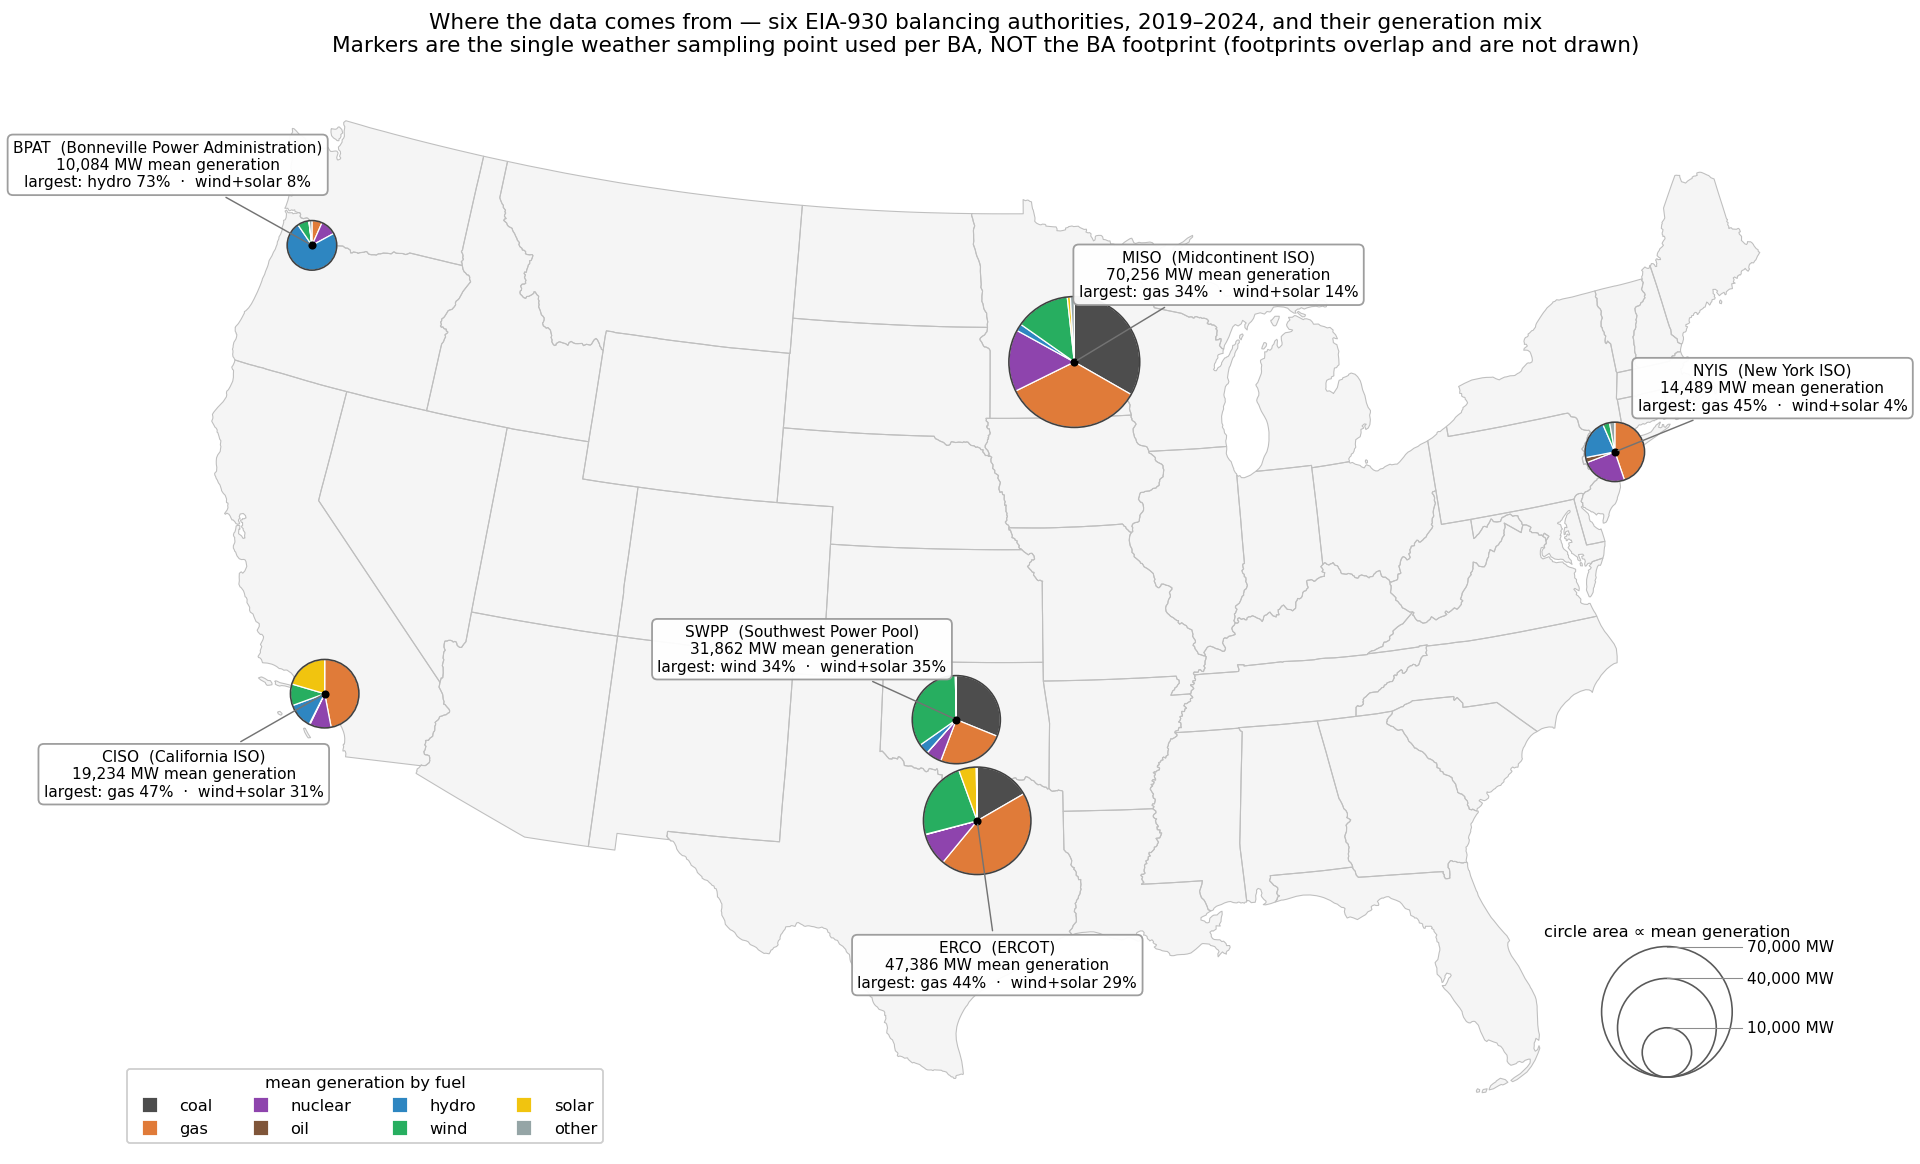

--- mean total generation and VRE share, by zone ---
      mean_generation_MW  wind_%  solar_%  wind+solar_% largest_fuel  largest_fuel_%
zone                                                                                
MISO             70256.0    13.5      0.8          14.3          gas            34.4
ERCO             47386.0    23.5      5.2          28.8          gas            44.3
SWPP             31862.0    34.4      0.2          34.6         wind            34.4
CISO             19234.0    10.2     20.4          30.6          gas            46.9
NYIS             14489.0     3.7      0.0           3.7          gas            44.7
BPAT             10084.0     7.5      0.2           7.7        hydro            73.4


In [8]:
# FIGURE 4 -- the six respondents on a US map, each a pie of its generation mix.
# WHY EPSG:5070: Albers Equal Area for the contiguous US. Plotting raw lat/lon would
#     stretch the north relative to the south, and since the pies encode magnitude by
#     AREA, an unequal-area projection would quietly misstate the comparison.
import geopandas as gpd
from matplotlib.patches import Wedge, Circle
from matplotlib.lines import Line2D

GEO = cfg.ROOT / 'data' / 'reference' / 'us_states_20m.geojson'
states = gpd.read_file(GEO).to_crs(5070)          # committed to the repo; no network

# The weather sampling points -- the ones actually used for the Open-Meteo pull.
from src.sources import BA_COORDS
pts = gpd.GeoDataFrame(
    {'zone': list(BA_COORDS)},
    geometry=gpd.points_from_xy([v[1] for v in BA_COORDS.values()],
                                [v[0] for v in BA_COORDS.values()]),
    crs=4326,
).to_crs(5070)
pts = pts.set_index('zone').loc[zones]
from math import asin, cos, radians, sin, sqrt
_la1, _lo1 = map(radians, BA_COORDS['SWPP'][:2]); _la2, _lo2 = map(radians, BA_COORDS['ERCO'][:2])
_km = 2 * 6371.0 * asin(sqrt(sin((_la2 - _la1) / 2) ** 2 + cos(_la1) * cos(_la2) * sin((_lo2 - _lo1) / 2) ** 2))
print(f"weather sampling points SWPP (Oklahoma City) to ERCO (Dallas): {_km:,.0f} km great-circle")

# Mean generation mix per zone. Negative means (the raw `other` column contains
# negative values) are clipped to 0 for the pie ONLY -- a wedge cannot subtend a
# negative angle. The raw values are untouched on disk and reported in figure 3.
mix_pos = mix.clip(lower=0)
totals = mix_pos.sum(axis=1)
frac = mix_pos.div(totals, axis=0)

# Radius encodes mean total generation by AREA: r proportional to sqrt(total).
# R_MAX is capped by the CLOSEST PAIR of sampling points: Oklahoma City (SWPP) and
# Dallas (ERCO) are ~300 km apart, so anything larger makes those two pies overlap
# and the figure starts lying about which slice belongs to which system.
R_MAX = 195_000                                    # metres
radii = np.sqrt(totals / totals.max()) * R_MAX

fig, ax = plt.subplots(figsize=(15, 9.5))
states.plot(ax=ax, color='0.96', edgecolor='none', zorder=0)
states.boundary.plot(ax=ax, linewidth=0.6, edgecolor='0.75', zorder=1)

# Label offsets in METRES, not multiples of the radius, so a small pie does not get
# a label sitting on top of it.
LABEL_OFFSET = {
    'BPAT': (-430_000,  240_000), 'CISO': (-420_000, -240_000),
    'SWPP': (-460_000,  210_000), 'ERCO': (  60_000, -430_000),
    'MISO': ( 430_000,  260_000), 'NYIS': ( 470_000,  190_000),
}

for z in zones:
    x, y = pts.loc[z].geometry.x, pts.loc[z].geometry.y
    r = radii[z]
    theta = 90.0                                   # start at 12 o'clock
    for f in FUELS:
        share_f = frac.loc[z, f]
        if share_f <= 0:
            continue
        d = 360.0 * share_f
        ax.add_patch(Wedge((x, y), r, theta - d, theta, facecolor=colors[f],
                           edgecolor='white', linewidth=0.7, zorder=3))
        theta -= d
    ax.add_patch(Circle((x, y), r, fill=False, edgecolor='0.25',
                        linewidth=0.9, zorder=4))
    ax.plot(x, y, marker='o', ms=3.5, color='black', zorder=5)

    dx, dy = LABEL_OFFSET[z]
    vre = 100 * (frac.loc[z, 'wind'] + frac.loc[z, 'solar'])
    top = frac.loc[z].idxmax()
    ax.annotate(f"{z}  ({RESPONDENTS[z].split('(')[0].strip()})\n"
                f"{totals[z]:,.0f} MW mean generation\n"
                f"largest: {top} {100 * frac.loc[z, top]:.0f}%  ·  wind+solar {vre:.0f}%",
                xy=(x, y), xytext=(x + dx, y + dy),
                ha='center', va='center', fontsize=8.5, zorder=6,
                bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='0.6', alpha=.95),
                arrowprops=dict(arrowstyle='-', color='0.45', lw=0.8))

# --- size key, drawn IN DATA COORDINATES ------------------------------------
# WHY not a normal legend: legend markers are sized in POINTS and the pies are sized
# in METRES, so a points-based key would only look right by coincidence and would
# silently misstate the scale at any other figure size. These are the same units as
# the map, so the key is correct by construction.
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
kx = x0 + 0.90 * (x1 - x0)
ky = y0 + 0.06 * (y1 - y0)
ax.text(kx, ky + 1.05 * R_MAX * 2, 'circle area ∝ mean generation',
        ha='center', va='bottom', fontsize=9)
for v in (70_000, 40_000, 10_000):
    rv = np.sqrt(v / totals.max()) * R_MAX
    # circles share a bottom tangent and are labelled at the TOP of each, so the
    # labels cannot collide however close two areas are
    ax.add_patch(Circle((kx, ky + rv), rv, fill=False, edgecolor='0.35',
                        linewidth=0.9, zorder=6))
    ax.plot([kx, kx + R_MAX + 30_000], [ky + 2 * rv, ky + 2 * rv],
            lw=0.6, color='0.55', zorder=6)
    ax.text(kx + R_MAX + 45_000, ky + 2 * rv, f'{v:,} MW', va='center',
            fontsize=8.5, zorder=6)

fuel_handles = [Line2D([], [], marker='s', ls='', ms=9, mfc=colors[f], mec='white',
                       label=f) for f in FUELS]
ax.legend(handles=fuel_handles, title='mean generation by fuel', ncol=4,
          loc='lower left', fontsize=9, title_fontsize=9, framealpha=.95)

ax.set_title('Where the data comes from — six EIA-930 balancing authorities, '
             '2019–2024, and their generation mix\n'
             'Markers are the single weather sampling point used per BA, NOT the BA '
             'footprint (footprints overlap and are not drawn)', fontsize=12)
ax.set_axis_off()
ax.margins(0.06)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_raw_map.png', bbox_inches='tight', dpi=cfg.DPI)
plt.show()

print("--- mean total generation and VRE share, by zone ---")
print(pd.DataFrame({
    'mean_generation_MW': totals.round(0),
    'wind_%': (100 * frac['wind']).round(1),
    'solar_%': (100 * frac['solar']).round(1),
    'wind+solar_%': (100 * (frac['wind'] + frac['solar'])).round(1),
    'largest_fuel': frac.idxmax(axis=1),
    'largest_fuel_%': (100 * frac.max(axis=1)).round(1),
}).sort_values('mean_generation_MW', ascending=False).to_string())

**What this shows:** Figure 4 (`00_raw_map`): one pie per BA at its weather point; circle area is proportional to mean total generation.

**What I see:** Sizes range from MISO (70,256 MW mean generation) to BPAT (10,084 MW). Geography matches fuel mix: the Great Plains systems are the wind-heaviest (SWPP 34.4%, the only zone whose largest fuel is a renewable; ERCO 23.5%), the Pacific Northwest is 73.4% hydro, California carries 20.4% solar, and NYIS has no solar wedge.

**What it means:** The zones are physically different systems, which supports pooling them into one model with `zone` as a feature. The map also makes the single-point weather limitation visible: MISO's point is in Minneapolis while its territory reaches Louisiana, and SWPP's footprint is far larger than Oklahoma City.

**What I do:** Record single-point weather as a limitation, worst for MISO and SWPP; the upgrade would be 3–4 load-weighted metro points per BA. Nothing in the data is changed.


#### Figures 5 and 6 — the weather dataset: where it was sampled, and what came back

Figure 5 shows the six ERA5 sampling points with their grid cells to scale; Figure 6 shows the weather columns themselves (annual cycle, daily cycle, completeness, spread per zone).

The target is `net_load = demand − wind − solar`, and weather drives all three: temperature moves demand, wind speed moves wind, cloud cover moves solar. In `src/features.py`, the fifteen ERA5 columns in `cfg.WEATHER_FEATURES` are passed to the model at the target hour, and lagged copies of some are added by `GroupLagFeatures` at a lag never shorter than the horizon. Same-hour weather is allowed, unlike same-hour `gas` or `coal`, because a weather forecast is available at the forecast origin. Notebook 01 measures these relationships.

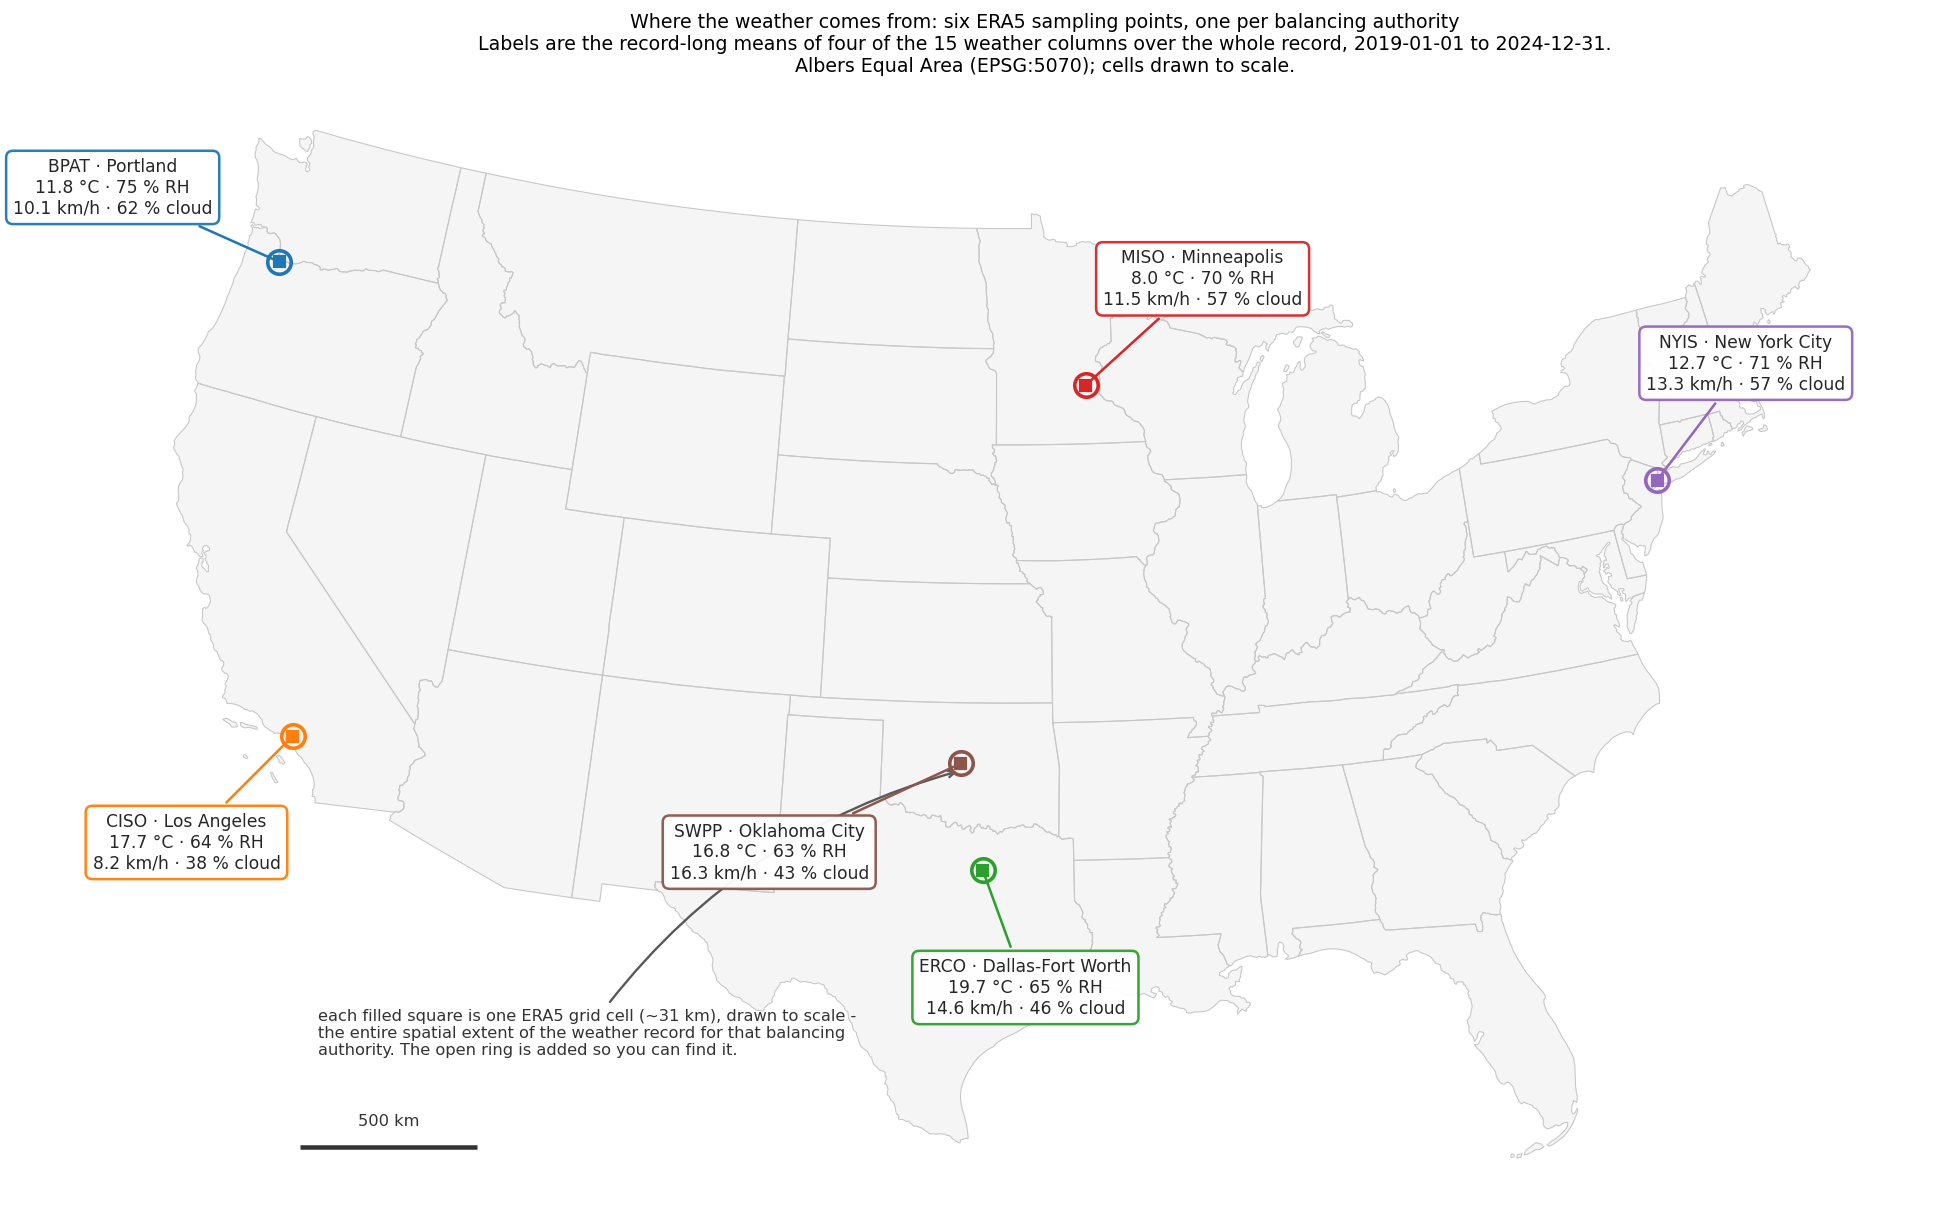

ERA5 sampling points. Labels average the whole record: 2019-01-01 to 2024-12-31.
This map shows no year-by-year variation -- that is figure 7.

ERA5 sampling points, and why each one:
  BPAT   45.52,  -122.68  Portland — BPA's dominant load centre; hydro and Columbia Gorge wind sit upstream of it.
  CISO   34.05,  -118.24  Los Angeles — the largest load centre inside CAISO; the LA basin drives the summer cooling peak.
  ERCO   32.78,   -96.80  Dallas-Fort Worth — the largest ERCOT metro; Houston is comparable and more humid, and is the named sensitivity check.
  MISO   44.98,   -93.27  Minneapolis — MISO's winter-peaking northern load. The weakest of the six choices: MISO spans to Louisiana.
  NYIS   40.71,   -74.01  New York City — NYISO Zone J is the load concentration; upstate is hydro-rich and much colder.
  SWPP   35.47,   -97.52  Oklahoma City — central to the SPP footprint and close to the wind corridor that sets its net load.


In [9]:
# FIGURE 5 -- where the weather comes from.
# WHAT: the six ERA5 sampling points, with each point's native grid cell drawn TO
#       SCALE against a continental map.
# WHY:  the single most important thing to understand about this half of the panel
#       is how little of a balancing authority one weather column represents. Said
#       in a sentence it sounds like a caveat; drawn to scale it is unmistakable.
# WHY EPSG:5070: Albers Equal Area, so a 31 km cell in Minnesota and one in Texas
#       are drawn the same size. In raw lat/lon the northern cells would be inflated.
import geopandas as gpd
from matplotlib.patches import Rectangle
from src.sources import BA_COORDS

GEO = cfg.ROOT / 'data' / 'reference' / 'us_states_20m.geojson'
states = gpd.read_file(GEO).to_crs(5070)
wpts = gpd.GeoDataFrame(
    {'zone': list(BA_COORDS)},
    geometry=gpd.points_from_xy([v[1] for v in BA_COORDS.values()],
                                [v[0] for v in BA_COORDS.values()]),
    crs=4326).to_crs(5070).set_index('zone').loc[zones]

CITY = {'CISO': 'Los Angeles', 'ERCO': 'Dallas-Fort Worth', 'MISO': 'Minneapolis',
        'SWPP': 'Oklahoma City', 'BPAT': 'Portland', 'NYIS': 'New York City'}
CZ = dict(zip(zones, plt.cm.tab10(np.linspace(0, 0.55, len(zones)))))
# The four the map annotation has room for. The full set is cfg.WEATHER_FEATURES
# (fifteen columns since 2026-08-23) and is inventoried in figure 6 panel (c).
Wc = ['temp', 'humidity', 'wind_speed', 'cloud_cover']
wmean = raw.groupby(cfg.GROUP_COL)[Wc].mean()
PERIOD = (f"{raw[cfg.TIME_COL].min():%Y-%m-%d} to "
          f"{raw[cfg.TIME_COL].max():%Y-%m-%d}")
CELL = 31_000.0        # ERA5 native grid spacing, metres
OFF = {'BPAT': (-470_000, 210_000), 'CISO': (-300_000, -300_000),
       'SWPP': (-540_000, -250_000), 'ERCO': (120_000, -330_000),
       'MISO': (330_000, 300_000), 'NYIS': (250_000, 330_000)}

fig, ax = plt.subplots(figsize=(15, 9.5))
states.plot(ax=ax, color='0.96', edgecolor='none', zorder=0)
states.boundary.plot(ax=ax, linewidth=0.6, edgecolor='0.78', zorder=1)
for z in zones:
    x, y = wpts.loc[z].geometry.x, wpts.loc[z].geometry.y
    ax.add_patch(Rectangle((x - CELL/2, y - CELL/2), CELL, CELL,
                           fc=CZ[z], ec=CZ[z], lw=1.2, zorder=5))
    ax.plot(x, y, 'o', ms=13, mfc='none', mec=CZ[z], mew=2.0, zorder=6)
    dx, dy = OFF[z]
    w_ = wmean.loc[z]
    ax.annotate(f'{z} · {CITY[z]}\n'
                f"{w_['temp']:.1f} °C · {w_['humidity']:.0f} % RH\n"
                f"{w_['wind_speed']:.1f} km/h · {w_['cloud_cover']:.0f} % cloud",
                xy=(x, y),
                xytext=(x + dx, y + dy), fontsize=9.5, color='0.15',
                ha='center', va='center', zorder=7,
                bbox=dict(fc='white', ec=CZ[z], lw=1.4, alpha=0.95,
                          boxstyle='round,pad=0.4'),
                arrowprops=dict(arrowstyle='-', color=CZ[z], lw=1.4))

x0, y0 = -2_000_000, 300_000
ax.plot([x0, x0 + 500_000], [y0, y0], '-', color='0.2', lw=2.5, solid_capstyle='butt')
ax.text(x0 + 250_000, y0 + 60_000, '500 km', ha='center', fontsize=9, color='0.2')
# Point the caption AT a real cell rather than drawing a legend key: at this scale a
# 31 km key square is smaller than the text describing it -- which is the point, but
# makes for a useless legend.
sx, sy = wpts.loc['SWPP'].geometry.x, wpts.loc['SWPP'].geometry.y
ax.annotate('each filled square is one ERA5 grid cell (~31 km), drawn to scale -\n'
            'the entire spatial extent of the weather record for that balancing\n'
            'authority. The open ring is added so you can find it.',
            xy=(sx, sy - 20_000), xytext=(-1_950_000, 620_000), fontsize=9,
            color='0.2', va='center',
            arrowprops=dict(arrowstyle='->', color='0.35', lw=1.3,
                            connectionstyle='arc3,rad=-0.18'))
ax.set_title('Where the weather comes from: six ERA5 sampling points, '
             'one per balancing authority\n'
             f'Labels are the record-long means of four of the 15 weather columns over the whole record, {PERIOD}.\n'
             'Albers Equal Area (EPSG:5070); cells drawn to scale.', fontsize=10.5)
ax.set_axis_off(); ax.set_xlim(-2_400_000, 2_600_000); ax.set_ylim(150_000, 3_300_000)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_weather_points_map.png', bbox_inches='tight')
plt.show()

print(f'ERA5 sampling points. Labels average the whole record: {PERIOD}.')
print('This map shows no year-by-year variation -- that is figure 7.\n')
print('ERA5 sampling points, and why each one:')
for z in zones:
    lat, lon, why = BA_COORDS[z]
    print(f'  {z}  {lat:6.2f}, {lon:8.2f}  {why}')

**What this shows:** Figure 5 (`00_weather_points_map`): the six coordinates sent to Open-Meteo, each with its ERA5 grid cell at true scale.

**What I see:** Each cell is about 31 km across. The points are major load centres (Los Angeles, Dallas–Fort Worth, Minneapolis, Oklahoma City, Portland, New York City), not geometric centroids.

**What it means:** Load centres are the right choice because they track where demand is, but one point represents large footprints poorly, and unevenly: well for NYIS and CISO, poorly for MISO and SWPP. Errors may therefore not be comparable across zones for reasons unrelated to the model.

**What I do:** Record it as a limitation; the upgrade path is noted in `src/sources.py`. Notebook 01 shows the cost: hub-height wind tracks wind output at r = +0.67 in MISO but only +0.05 in BPAT.

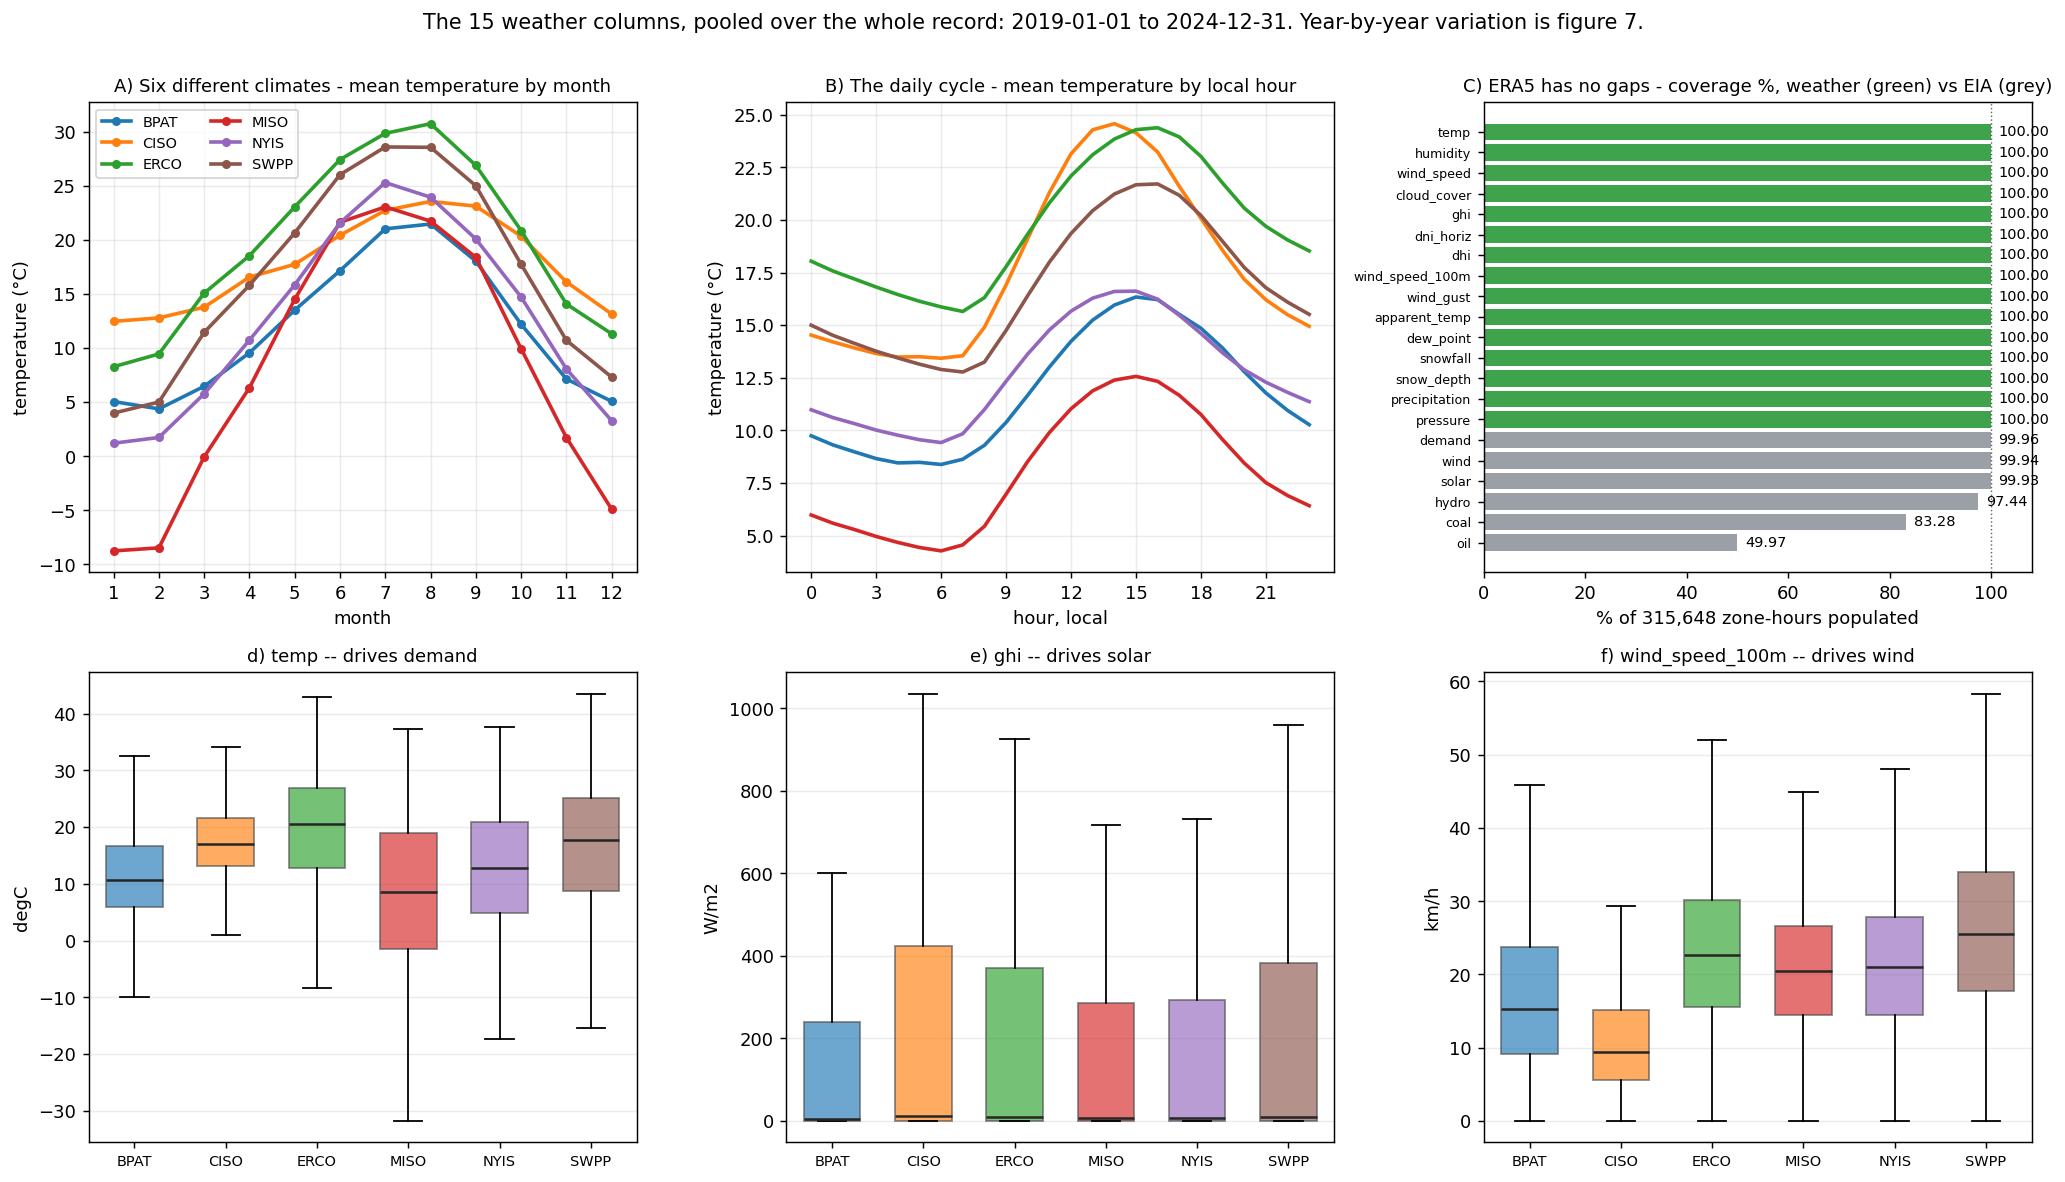

annual and daily temperature range by zone:
  BPAT: annual    4.4 (m2) ->  21.5 (m8)  swing  17.1 C | daily swing  8.0 C
  CISO: annual   12.5 (m1) ->  23.5 (m8)  swing  11.1 C | daily swing 11.1 C
  ERCO: annual    8.3 (m1) ->  30.7 (m8)  swing  22.5 C | daily swing  8.7 C
  MISO: annual   -8.7 (m1) ->  23.0 (m7)  swing  31.8 C | daily swing  8.3 C


  NYIS: annual    1.2 (m1) ->  25.3 (m7)  swing  24.1 C | daily swing  7.2 C
  SWPP: annual    4.0 (m1) ->  28.6 (m7)  swing  24.6 C | daily swing  8.9 C

coverage, all 15 weather columns:
  temp               100.00%   mean     14.46  sd    10.52
  humidity           100.00%   mean     67.92  sd    20.56
  wind_speed         100.00%   mean     12.35  sd     7.08
  cloud_cover        100.00%   mean     50.73  sd    43.49
  ghi                100.00%   mean    184.99  sd   265.43
  dni_horiz          100.00%   mean    128.01  sd   214.91
  dhi                100.00%   mean     56.98  sd    78.71
  wind_speed_100m    100.00%   mean     20.07  sd    11.10
  wind_gust          100.00%   mean     24.02  sd    12.33
  apparent_temp      100.00%   mean     12.81  sd    12.61
  dew_point          100.00%   mean      7.70  sd     9.62
  snowfall           100.00%   mean      0.00  sd     0.06


  snow_depth         100.00%   mean      0.01  sd     0.05
  precipitation      100.00%   mean      0.12  sd     0.69
  pressure           100.00%   mean    998.56  sd    16.24


[results read-only] nb00: 1 key(s) verified against the ledger, nothing written


{'_keys_run_id': {'artefact': '65f15ccddc33',
  'disk_mb': '65f15ccddc33',
  'duck_curve': '65f15ccddc33',
  'end': '65f15ccddc33',
  'forecast_weather': '65f15ccddc33',
  'hours_in_window': '65f15ccddc33',
  'panel_hash': '65f15ccddc33',
  'price_markets_obtained': '65f15ccddc33',
  'price_rows': '65f15ccddc33',
  'price_status_by_zone': '65f15ccddc33',
  'price_window': '65f15ccddc33',
  'raw_columns': '65f15ccddc33',
  'raw_rows': '65f15ccddc33',
  'rows_per_zone': '65f15ccddc33',
  'source': '65f15ccddc33',
  'start': '65f15ccddc33',
  'temp_coverage': '65f15ccddc33',
  'weather': '65f15ccddc33',
  'weather_by_year': '65f15ccddc33',
  'zones': '65f15ccddc33'},
 '_keys_written_at': {'artefact': '2026-09-29T07:25:25+00:00',
  'disk_mb': '2026-09-29T07:25:25+00:00',
  'duck_curve': '2026-09-29T07:25:21+00:00',
  'end': '2026-09-29T07:25:25+00:00',
  'forecast_weather': '2026-09-29T07:25:25+00:00',
  'hours_in_window': '2026-09-29T07:25:25+00:00',
  'panel_hash': '2026-09-29T07:25:25+0

In [10]:
# FIGURE 6 -- what the weather columns actually contain.
# WHAT: (a) annual cycle, (b) daily cycle in LOCAL time, (c) completeness against
#       the EIA columns, (d-f) the spread each zone sees in each variable.
# WHY:  the modelling claim is that weather carries information about net load. That
#       is only possible if the weather columns themselves vary in the ways the
#       physics requires -- seasonally, daily, and differently per zone. This is the
#       evidence for that precondition, before any relationship is measured.
# NOTE: LOCAL time in panel (b) via cfg.ZONE_TZ. Drawn in UTC, each zone's afternoon
#       peak would sit at a different clock hour (three US time zones) and be blurred
#       by an hour at every DST change.
# WIDENED 2026-08-23 from four columns to fifteen. Panel (c) inventories all of
# them; panels (d)-(f) show the three that drive the three terms of net load --
# temperature drives demand, irradiance drives solar, hub-height wind drives wind
# -- because fifteen box panels would be an inventory rather than a figure.
Wc = list(cfg.WEATHER_FEATURES)
WBOX = [('temp', 'd) temp -- drives demand', 'degC'),
        ('ghi', 'e) ghi -- drives solar', 'W/m2'),
        ('wind_speed_100m', 'f) wind_speed_100m -- drives wind', 'km/h')]
dw = raw.copy()
lh = pd.Series(index=dw.index, dtype='float64')
for z, tz in cfg.ZONE_TZ.items():
    m = dw[cfg.GROUP_COL] == z
    lh[m] = dw.loc[m, cfg.TIME_COL].dt.tz_localize('UTC').dt.tz_convert(tz).dt.hour.values
dw['lh'], dw['month'] = lh, dw[cfg.TIME_COL].dt.month

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
ax = axes[0, 0]
for z in zones:
    s = dw[dw[cfg.GROUP_COL] == z].groupby('month')['temp'].mean()
    ax.plot(s.index, s.values, 'o-', ms=4, lw=2, color=CZ[z], label=z)
ax.set_title('A) Six different climates - mean temperature by month', fontsize=10)
ax.set_xlabel('month'); ax.set_ylabel('temperature (°C)')
ax.set_xticks(range(1, 13)); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.25)

ax = axes[0, 1]
for z in zones:
    s = dw[dw[cfg.GROUP_COL] == z].groupby('lh')['temp'].mean()
    ax.plot(s.index, s.values, '-', lw=2, color=CZ[z], label=z)
ax.set_title('B) The daily cycle - mean temperature by local hour', fontsize=10)
ax.set_xlabel('hour, local'); ax.set_ylabel('temperature (°C)')
ax.set_xticks(range(0, 24, 3)); ax.grid(alpha=0.25)

ax = axes[0, 2]
ccols = Wc + ['demand', 'wind', 'solar', 'hydro', 'coal', 'oil']
cov = [raw[c].notna().mean() * 100 for c in ccols]
ax.barh(range(len(ccols)), cov,
        color=['#3fa34d'] * len(Wc) + ['#9aa0a6'] * (len(ccols) - len(Wc)))
ax.set_yticks(range(len(ccols))); ax.set_yticklabels(ccols, fontsize=7)
ax.invert_yaxis(); ax.set_xlim(0, 108); ax.axvline(100, color='0.4', lw=0.8, ls=':')
for i, v in enumerate(cov):
    ax.text(v + 1.5, i, f'{v:.2f}', va='center', fontsize=8)
ax.set_title('C) ERA5 has no gaps - coverage %, weather (green) vs EIA (grey)', fontsize=10)
ax.set_xlabel(f'% of {len(raw):,} zone-hours populated')

def _box(ax, col, title, ylab):
    data = [dw[dw[cfg.GROUP_COL] == z][col].dropna().values for z in zones]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.62)
    for patch, z in zip(bp['boxes'], zones):
        patch.set_facecolor(CZ[z]); patch.set_alpha(0.65); patch.set_edgecolor('0.3')
    for med in bp['medians']:
        med.set_color('0.15'); med.set_linewidth(1.4)
    ax.set_xticklabels(zones, fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylab); ax.grid(alpha=0.25, axis='y')

for ax_, (col_, title_, unit_) in zip(axes[1], WBOX):
    _box(ax_, col_, title_, unit_)
fig.suptitle(f'The {len(Wc)} weather columns, pooled over the whole record: '
             f'{raw[cfg.TIME_COL].min():%Y-%m-%d} to {raw[cfg.TIME_COL].max():%Y-%m-%d}. '
             f'Year-by-year variation is figure 7.', fontsize=11.5, y=1.005)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_weather_dataset.png', bbox_inches='tight')
plt.show()

print('annual and daily temperature range by zone:')
for z in zones:
    m = dw[dw[cfg.GROUP_COL] == z].groupby('month')['temp'].mean()
    h = dw[dw[cfg.GROUP_COL] == z].groupby('lh')['temp'].mean()
    print(f'  {z}: annual {m.min():6.1f} (m{m.idxmin()}) -> {m.max():5.1f} (m{m.idxmax()})'
          f'  swing {m.max()-m.min():5.1f} C | daily swing {h.max()-h.min():4.1f} C')
print('\ncoverage, all ' + str(len(Wc)) + ' weather columns:')
for c in Wc:
    print(f'  {c:18s} {raw[c].notna().mean()*100:6.2f}%   '
          f'mean {raw[c].mean():9.2f}  sd {raw[c].std():8.2f}')

R.save('nb00', {'weather': {
    'source': 'Open-Meteo ERA5 (ECMWF reanalysis)',
    'points': {z: {'lat': BA_COORDS[z][0], 'lon': BA_COORDS[z][1],
                   'city': CITY[z], 'why': BA_COORDS[z][2]} for z in zones},
    'grid_cell_km': 31,
    'columns': Wc,
    'n_columns': len(Wc),
    'column_mean': {c: float(raw[c].mean()) for c in Wc},
    'column_sd': {c: float(raw[c].std()) for c in Wc},
    'coverage_pct': {c: float(raw[c].notna().mean() * 100) for c in Wc},
    'mean_temp_c': {z: float(wmean.loc[z, 'temp']) for z in zones},
    'annual_swing_c': {z: float(dw[dw[cfg.GROUP_COL] == z].groupby('month')['temp'].mean().max()
                                - dw[dw[cfg.GROUP_COL] == z].groupby('month')['temp'].mean().min())
                       for z in zones},
    'daily_swing_c': {z: float(dw[dw[cfg.GROUP_COL] == z].groupby('lh')['temp'].mean().max()
                               - dw[dw[cfg.GROUP_COL] == z].groupby('lh')['temp'].mean().min())
                      for z in zones},
}})

**What this shows:** Figure 6 (`00_weather_dataset`): (a) mean temperature by month, (b) by local hour, (c) share of the 315,648 zone-hours populated, weather vs EIA columns, (d)–(f) box plots of `temp`, `ghi` and `wind_speed_100m` per zone.

**What I see:** The six climates differ: MISO swings 31.8 °C across the year (−8.7 to 23.0 °C), CISO only 11.1 °C. Daily cycles peak mid-afternoon local time; CISO's daily swing is largest (11.1 °C), NYIS's smallest (7.2 °C). All fifteen weather columns are **100.00%** complete, against `demand` 99.96%, `coal` 83.28% and `oil` 49.97%. Record extremes run from −38.3 °C (MISO) to 46.0 °C (BPAT).

**What it means:** Weather varies seasonally, daily and between zones, which it must if it is to explain net load. Because ERA5 is a model output, it has no gaps, so no weather value in this project is imputed.

**What I do:** Keep all fifteen columns as features; the tuned model keeps every column (`select__k = "all"`). Local time is used for figures only; the model stays in UTC.


#### Figure 7 — does the weather change year to year, and does the split care?

Annual means of four weather columns per zone, then two panels on what this means for the train/holdout split. Six annual means are too few to read a trend; panel (f) is the useful part.

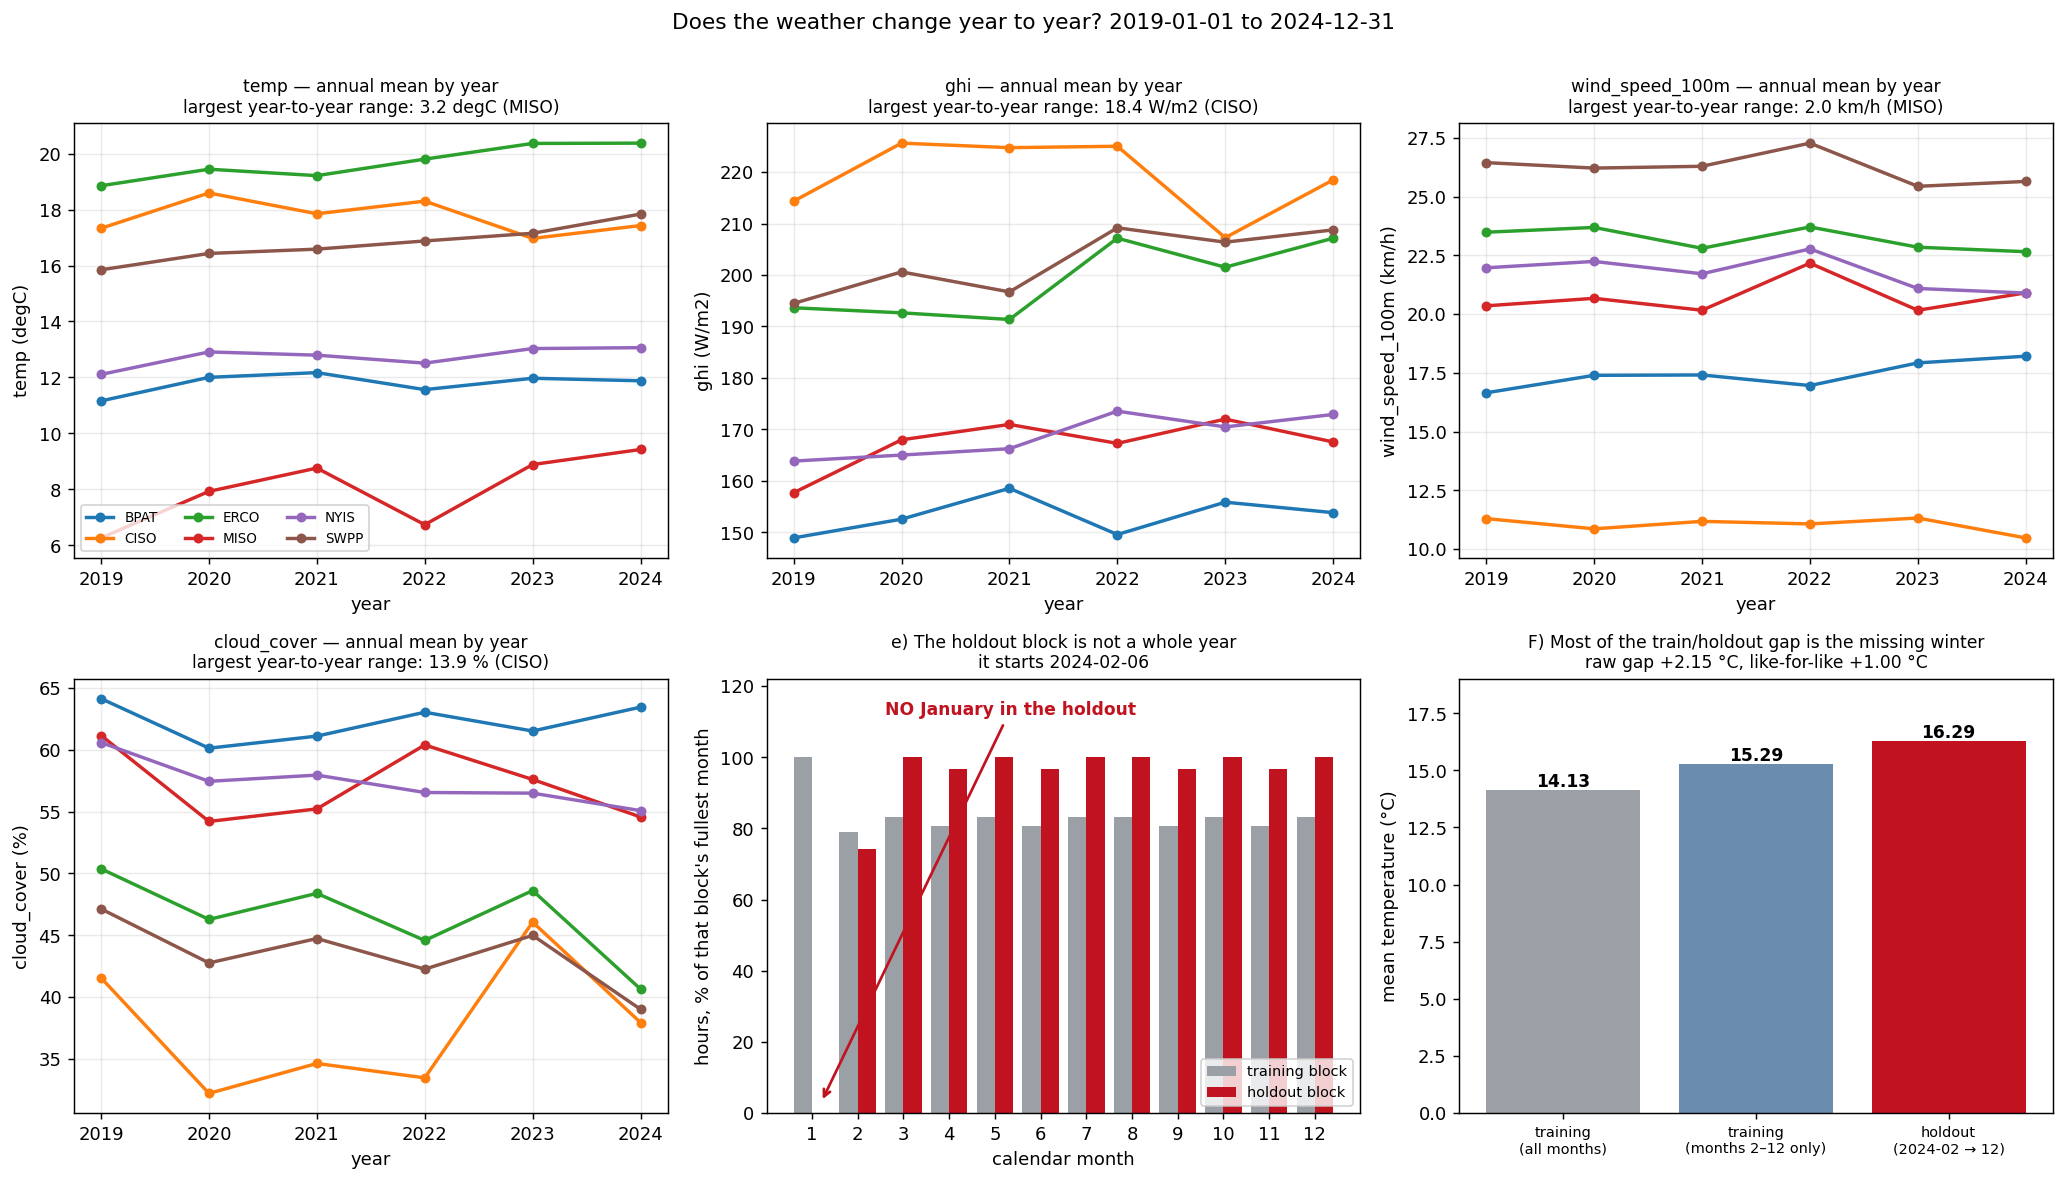

temp         year-to-year range (degC): BPAT 1.01, CISO 1.62, ERCO 1.52, MISO 3.16, NYIS 0.96, SWPP 1.99
ghi          year-to-year range (W/m2): BPAT 9.64, CISO 18.37, ERCO 15.80, MISO 14.30, NYIS 9.70, SWPP 14.69
wind_speed_100m year-to-year range (km/h): BPAT 1.56, CISO 0.85, ERCO 1.05, MISO 2.01, NYIS 1.88, SWPP 1.84


cloud_cover  year-to-year range (%): BPAT 4.01, CISO 13.86, ERCO 9.73, MISO 6.95, NYIS 5.51, SWPP 8.12

holdout starts 2024-02-06 23:00; January hours in it: 0
mean temp  train(all months) 14.13 | train(months 2-12) 15.29 | holdout 16.29 °C


[results read-only] nb00: 1 key(s) verified against the ledger, nothing written


{'_keys_run_id': {'artefact': '65f15ccddc33',
  'disk_mb': '65f15ccddc33',
  'duck_curve': '65f15ccddc33',
  'end': '65f15ccddc33',
  'forecast_weather': '65f15ccddc33',
  'hours_in_window': '65f15ccddc33',
  'panel_hash': '65f15ccddc33',
  'price_markets_obtained': '65f15ccddc33',
  'price_rows': '65f15ccddc33',
  'price_status_by_zone': '65f15ccddc33',
  'price_window': '65f15ccddc33',
  'raw_columns': '65f15ccddc33',
  'raw_rows': '65f15ccddc33',
  'rows_per_zone': '65f15ccddc33',
  'source': '65f15ccddc33',
  'start': '65f15ccddc33',
  'temp_coverage': '65f15ccddc33',
  'weather': '65f15ccddc33',
  'weather_by_year': '65f15ccddc33',
  'zones': '65f15ccddc33'},
 '_keys_written_at': {'artefact': '2026-09-29T07:25:25+00:00',
  'disk_mb': '2026-09-29T07:25:25+00:00',
  'duck_curve': '2026-09-29T07:25:21+00:00',
  'end': '2026-09-29T07:25:25+00:00',
  'forecast_weather': '2026-09-29T07:25:25+00:00',
  'hours_in_window': '2026-09-29T07:25:25+00:00',
  'panel_hash': '2026-09-29T07:25:25+0

In [11]:
# FIGURE 7 -- year-by-year, and what it means for the split.
# WHAT: (a-d) annual mean of each weather column, per zone, per year.
#       (e) the holdout block's calendar-month coverage against the training block.
#       (f) how much of the train/holdout temperature gap is simply missing winter.
# WHY:  figures 5 and 6 pool all six years. That is the right default for describing
#       a record, and it hides the one thing the SPLIT is sensitive to.
# NOTE: six annual means is not enough to establish a trend, and this cell
#       deliberately does not fit one. See the interpretation.
# The four PLOTTED, chosen for the three drivers of net load plus cloud, the proxy
# whose forecast error is largest relative to its mean (table in section 0.6b). The
# year-to-year range is SAVED for all fifteen -- the figure is a selection, the
# record is not.
Wu = [('temp', 'degC'), ('ghi', 'W/m2'), ('wind_speed_100m', 'km/h'),
      ('cloud_cover', '%')]
WALL = list(cfg.WEATHER_FEATURES)
raw_y = raw.assign(yr=raw[cfg.TIME_COL].dt.year)
YEARS = sorted(raw_y['yr'].unique())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (w, unit) in zip(axes.ravel()[:4], Wu):
    tab = raw_y.pivot_table(index='yr', columns=cfg.GROUP_COL, values=w, aggfunc='mean')
    for z in zones:
        ax.plot(tab.index, tab[z], 'o-', ms=4.5, lw=1.9, color=CZ[z], label=z)
    spread = tab.max() - tab.min()
    ax.set_title(f'{w} — annual mean by year\nlargest year-to-year range: '
                 f'{spread.max():.1f} {unit} ({spread.idxmax()})', fontsize=9.5)
    ax.set_xlabel('year'); ax.set_ylabel(f'{w} ({unit})')
    ax.set_xticks(YEARS); ax.grid(alpha=0.25)
axes[0, 0].legend(fontsize=7.5, ncol=3)

# (e) the seasonal hole in the holdout block
ax = axes[1, 1]
cut = cfg.HOLDOUT_CUT
tr, te = raw[raw[cfg.TIME_COL] <= cut], raw[raw[cfg.TIME_COL] > cut]
mt = te[cfg.TIME_COL].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
mr = tr[cfg.TIME_COL].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
xm = np.arange(1, 13)
ax.bar(xm - 0.2, mr / mr.max() * 100, 0.4, label='training block', color='#9aa0a6')
ax.bar(xm + 0.2, mt / mt.max() * 100, 0.4, label='holdout block', color='#c1121f')
ax.set_ylim(0, 122)
ax.annotate('NO January in the holdout', xy=(1.2, 3), xytext=(2.6, 112), fontsize=9.5,
            color='#c1121f', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#c1121f', lw=1.5))
ax.set_xticks(xm); ax.set_xlabel('calendar month')
ax.set_ylabel("hours, % of that block's fullest month")
ax.set_title(f'e) The holdout block is not a whole year\nit starts {cut:%Y-%m-%d}',
             fontsize=9.5)
ax.legend(fontsize=8, loc='lower right')

# (f) decompose the train/holdout gap
ax = axes[1, 2]
months = sorted(mt[mt > 0].index)
trm = tr[tr[cfg.TIME_COL].dt.month.isin(months)]
vals = [tr['temp'].mean(), trm['temp'].mean(), te['temp'].mean()]
ax.bar(range(3), vals, color=['#9aa0a6', '#6a8caf', '#c1121f'])
for i_, v in enumerate(vals):
    ax.text(i_, v + 0.15, f'{v:.2f}', ha='center', fontsize=9.5, fontweight='bold')
ax.set_xticks(range(3))
ax.set_xticklabels(['training\n(all months)',
                    f'training\n(months {months[0]}–{months[-1]} only)',
                    'holdout\n(2024-02 → 12)'], fontsize=8)
ax.set_ylabel('mean temperature (°C)'); ax.set_ylim(0, 19)
ax.set_title('F) Most of the train/holdout gap is the missing winter\n'
             f'raw gap {vals[2]-vals[0]:+.2f} °C, like-for-like {vals[2]-vals[1]:+.2f} °C',
             fontsize=9.5)

fig.suptitle(f'Does the weather change year to year? '
             f'{raw[cfg.TIME_COL].min():%Y-%m-%d} to {raw[cfg.TIME_COL].max():%Y-%m-%d}',
             fontsize=12, y=1.005)
plt.tight_layout()
plt.savefig(cfg.FIGURES / '00_weather_by_year.png', bbox_inches='tight')
plt.show()

for w, unit in Wu:
    tab = raw_y.pivot_table(index='yr', columns=cfg.GROUP_COL, values=w, aggfunc='mean')
    sp = tab.max() - tab.min()
    print(f'{w:12s} year-to-year range ({unit}): '
          + ', '.join(f'{z} {sp[z]:.2f}' for z in zones))
print(f'\nholdout starts {cut:%Y-%m-%d %H:%M}; January hours in it: {int(mt[1])}')
print(f'mean temp  train(all months) {vals[0]:.2f} | train(months {months[0]}-{months[-1]}) '
      f'{vals[1]:.2f} | holdout {vals[2]:.2f} °C')

R.save('nb00', {'weather_by_year': {
    'period': [str(raw[cfg.TIME_COL].min()), str(raw[cfg.TIME_COL].max())],
    'annual_mean': {w: raw_y.pivot_table(index='yr', columns=cfg.GROUP_COL, values=w,
                                         aggfunc='mean').round(3).to_dict()
                    for w, _ in Wu},
    'year_to_year_range': {w: {z: float((lambda t: t.max() - t.min())(
        raw_y.pivot_table(index='yr', columns=cfg.GROUP_COL, values=w, aggfunc='mean')[z]))
        for z in zones} for w in WALL},
    'holdout_starts': str(cut),
    'holdout_january_hours': int(mt[1]),
    'holdout_months_present': [int(m) for m in months],
    'mean_temp_train_all_c': float(vals[0]),
    'mean_temp_train_same_months_c': float(vals[1]),
    'mean_temp_holdout_c': float(vals[2]),
}})

**What this shows:** Figure 7 (`00_weather_by_year`): (a)–(d) annual mean of `temp`, `ghi`, `wind_speed_100m` and `cloud_cover` per zone. (e) month composition of the training and holdout blocks. (f) mean training temperature over all months, over the holdout's months only, and the holdout itself.

**What I see:** Temperature is steady year to year (widest range MISO, 3.2 °C) and wind steadier still, but irradiance and cloud cover move more (CISO cloud cover ranges 13.9 points). The holdout starts 2024-02-07 and contains **zero January hours**. It looks **+2.16 °C** warmer than training, but only **+1.00 °C** when comparing the same months.

**What it means:** This dataset cannot show a climate trend; the variation is interannual. The split matters more: about half the train/holdout temperature gap comes from the missing January, so the holdout score is not representative of a full year, especially for heating-driven zones.

**What I do:** Keep the split. Notebook 04 reports holdout error by season, the limitation (February–December 2024) is stated, and CV-vs-holdout comparisons are treated as confounded by season.


### 0.6 — The duck curve: the problem this project exists to forecast

The shape of an average CISO day in **local** time: demand against net load, how it changed since 2019, the evening ramp, and whether other zones share it. This is why the target is `net_load` rather than `demand`. The panel and model stay in UTC; local time (`cfg.ZONE_TZ`) is used for figures only, because the evening ramp follows people's clocks. Profiles are **medians**, which are robust to the raw defects (median overnight solar is still about −25 MW, a metering artefact).

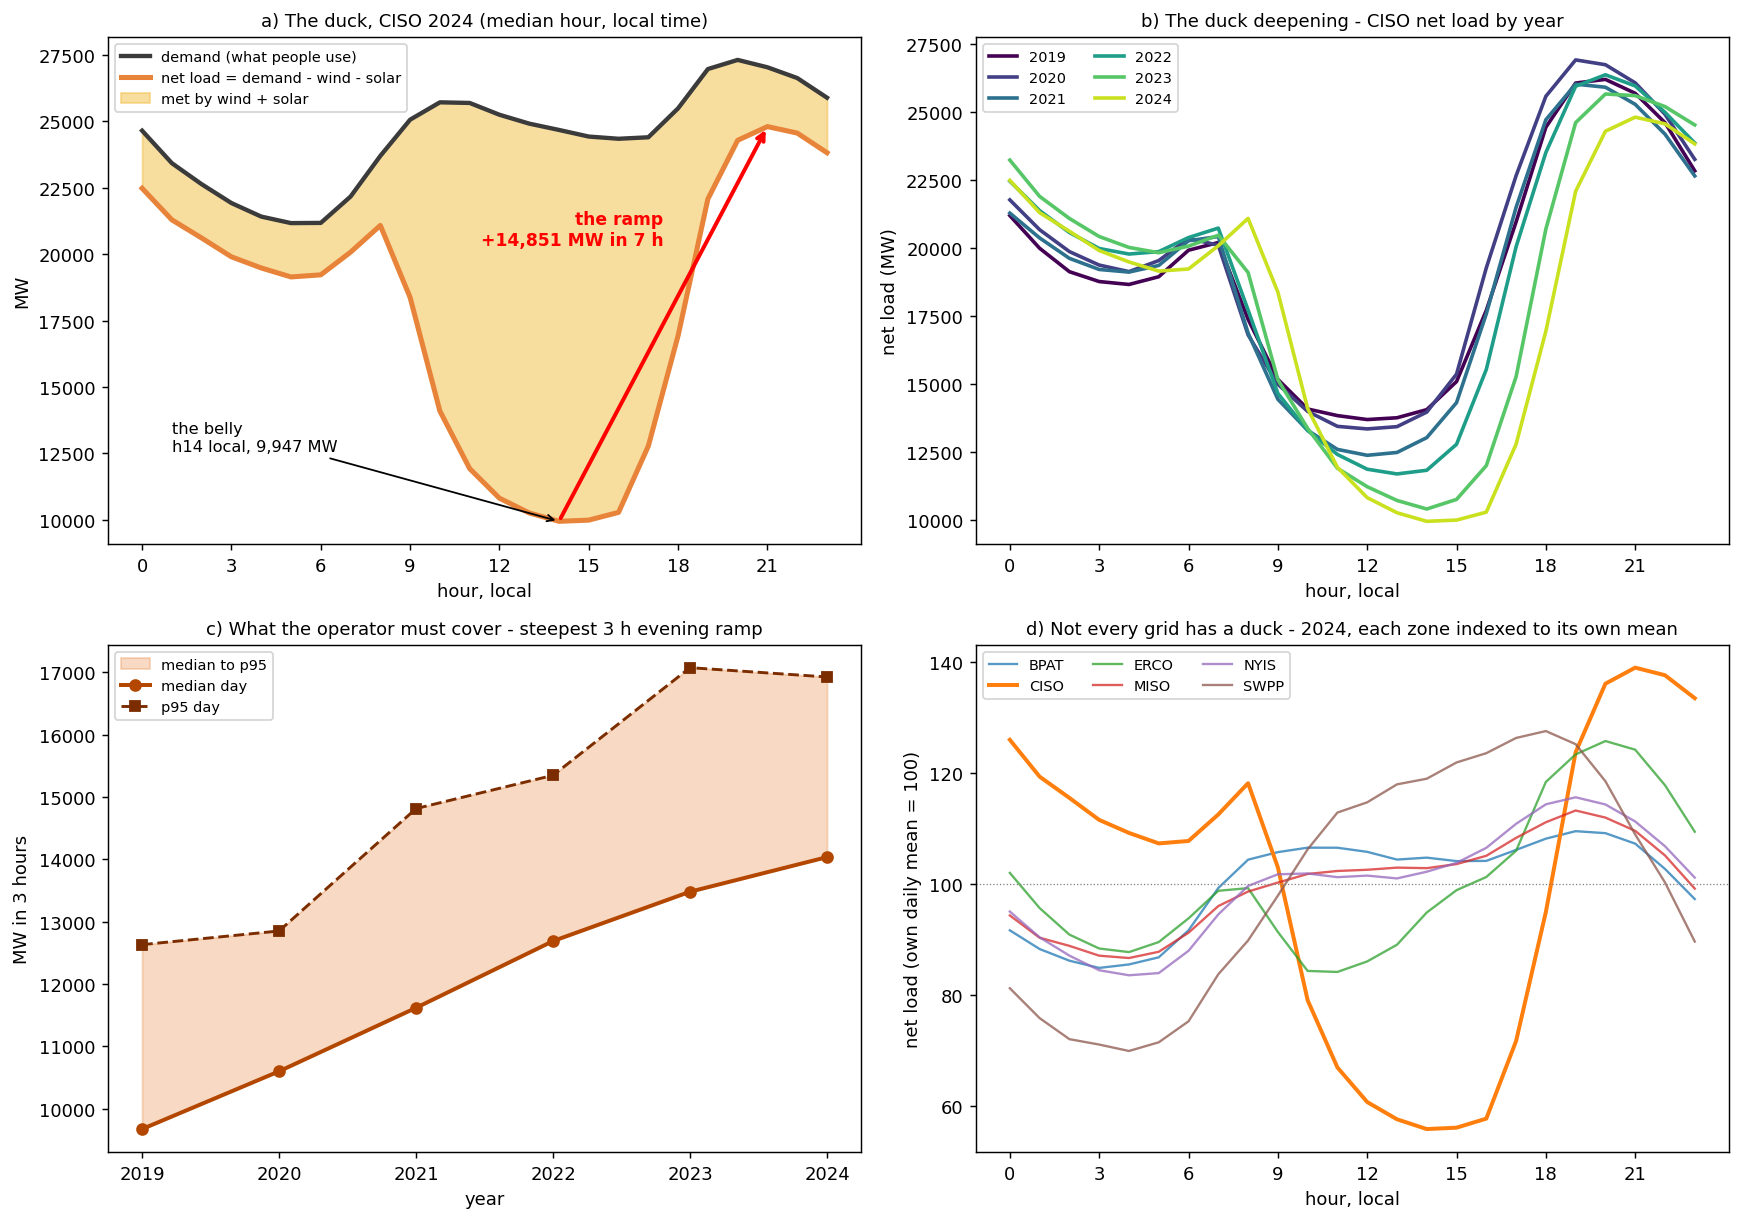

CISO 2024 median day: demand swings 6,140 MW, net load swings 14,851 MW  (x2.4)
  2019: trough h12 13,687 MW | peak h20 26,187 MW
  2024: trough h14 9,947 MW | peak h21 24,798 MW
steepest 3 h evening ramp, median day: 9,676 -> 14,036 MW (+45%); p95 day 12,633 -> 16,924 MW

trough hour by zone, 2024 (local): BPAT h03, CISO h14, ERCO h11, MISO h04, NYIS h04, SWPP h04
[results read-only] nb00: 1 key(s) verified against the ledger, nothing written


{'_keys_run_id': {'artefact': '65f15ccddc33',
  'disk_mb': '65f15ccddc33',
  'duck_curve': '65f15ccddc33',
  'end': '65f15ccddc33',
  'forecast_weather': '65f15ccddc33',
  'hours_in_window': '65f15ccddc33',
  'panel_hash': '65f15ccddc33',
  'price_markets_obtained': '65f15ccddc33',
  'price_rows': '65f15ccddc33',
  'price_status_by_zone': '65f15ccddc33',
  'price_window': '65f15ccddc33',
  'raw_columns': '65f15ccddc33',
  'raw_rows': '65f15ccddc33',
  'rows_per_zone': '65f15ccddc33',
  'source': '65f15ccddc33',
  'start': '65f15ccddc33',
  'temp_coverage': '65f15ccddc33',
  'weather': '65f15ccddc33',
  'weather_by_year': '65f15ccddc33',
  'zones': '65f15ccddc33'},
 '_keys_written_at': {'artefact': '2026-09-29T07:25:25+00:00',
  'disk_mb': '2026-09-29T07:25:25+00:00',
  'duck_curve': '2026-09-29T07:25:21+00:00',
  'end': '2026-09-29T07:25:25+00:00',
  'forecast_weather': '2026-09-29T07:25:25+00:00',
  'hours_in_window': '2026-09-29T07:25:25+00:00',
  'panel_hash': '2026-09-29T07:25:25+0

In [12]:
# FIGURE 8 -- the duck curve: why net load, and not demand, is the target.
# WHAT: (a) CISO's median day in 2024, demand vs net load; (b) the same profile per
#       year since 2019; (c) the steepest 3-hour evening ramp per day, by year;
#       (d) all six zones in 2024, each indexed to its own daily mean.
# WHY:  this figure is the project's premise, stated as evidence rather than as a
#       claim the project makes.
# NOTE: MEDIAN, not mean -- notebook 00 has cleaned nothing, and the median survives the
#       defective hours notebook 01 will null. And LOCAL time via cfg.ZONE_TZ: the evening
#       ramp follows the local clock, which moves an hour against UTC at each DST change.
YEARS = list(range(2019, 2025))

def local_frame(z):
    """Zone slice with local hour/year attached. Presentation only -- never a feature."""
    d = raw[raw[cfg.GROUP_COL] == z].copy()
    loc = d[cfg.TIME_COL].dt.tz_localize("UTC").dt.tz_convert(cfg.ZONE_TZ[z])
    d["lh"], d["yr"], d["local"] = loc.dt.hour, loc.dt.year, loc
    d["net"] = d["demand"] - d["wind"] - d["solar"]
    # The UTC->local shift pulls a few hours of 2018-12-31 into view. Drop them:
    # a year represented by 8 hours would sit in panel (c) as a fake data point.
    return d[d["yr"].isin(YEARS)]

c = local_frame("CISO")
p24 = c[c["yr"] == 2024].groupby("lh")[["demand", "net"]].median()

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5))
ax = axes[0, 0]
ax.plot(p24.index, p24["demand"], lw=2.4, color="#3b3b3b", label="demand (what people use)")
ax.plot(p24.index, p24["net"], lw=2.8, color="#e8833a", label="net load = demand - wind - solar")
ax.fill_between(p24.index, p24["net"], p24["demand"], color="#f2c14e", alpha=0.55,
                label="met by wind + solar")
lo, hi = p24["net"].idxmin(), p24["net"].idxmax()
ax.annotate("", xy=(hi, p24.loc[hi, "net"]), xytext=(lo, p24.loc[lo, "net"]),
            arrowprops=dict(arrowstyle="->", color="red", lw=2.2))
ax.annotate(f"the ramp\n+{p24.loc[hi,'net']-p24.loc[lo,'net']:,.0f} MW in {hi-lo} h",
            xy=(hi - 3.5, (p24.loc[lo, "net"] + p24.loc[hi, "net"]) / 2
                + 0.24 * (p24.loc[hi, "net"] - p24.loc[lo, "net"])),
            ha="right", va="center", color="red", fontsize=9.5, fontweight="bold")   # above the arrow, not on it
ax.annotate(f"the belly\nh{lo} local, {p24.loc[lo,'net']:,.0f} MW",
            xy=(lo, p24.loc[lo, "net"]), xytext=(1.0, 12600), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="black", lw=1))
ax.set_title("a) The duck, CISO 2024 (median hour, local time)", fontsize=10)
ax.set_xlabel("hour, local"); ax.set_ylabel("MW")
ax.legend(fontsize=8, loc="upper left"); ax.set_xticks(range(0, 24, 3))

ax = axes[0, 1]
for col, yr in zip(plt.cm.viridis(np.linspace(0, 0.92, len(YEARS))), YEARS):
    py = c[c["yr"] == yr].groupby("lh")["net"].median()
    ax.plot(py.index, py.values, lw=2.0, color=col, label=str(yr))
ax.set_title("b) The duck deepening - CISO net load by year", fontsize=10)
ax.set_xlabel("hour, local"); ax.set_ylabel("net load (MW)")
ax.legend(fontsize=8, ncol=2); ax.set_xticks(range(0, 24, 3))

ax = axes[1, 0]
s = c.set_index("local")["net"].sort_index()
d3 = s.diff(3)
ev = d3[(d3.index.hour >= 15) & (d3.index.hour <= 21)]
day_max = ev.groupby(ev.index.date).max()
day_max.index = pd.to_datetime(day_max.index)
g = day_max.groupby(day_max.index.year)
med, p95 = g.median(), g.quantile(0.95)
med, p95 = med[med.index.isin(YEARS)], p95[p95.index.isin(YEARS)]
ax.fill_between(med.index, med.values, p95.values, color="#e8833a", alpha=0.3,
                label="median to p95")
ax.plot(med.index, med.values, "o-", color="#b34700", lw=2.2, label="median day")
ax.plot(p95.index, p95.values, "s--", color="#7b2d00", lw=1.6, label="p95 day")
ax.set_title("c) What the operator must cover - steepest 3 h evening ramp", fontsize=10)
ax.set_xlabel("year"); ax.set_ylabel("MW in 3 hours"); ax.legend(fontsize=8)

ax = axes[1, 1]
zone_shape = {}
for z in sorted(cfg.ZONE_TZ):
    dz = local_frame(z)
    py = dz[dz["yr"] == 2024].groupby("lh")["net"].median()
    idx = py / py.mean() * 100
    zone_shape[z] = idx
    ax.plot(idx.index, idx.values, lw=2.2 if z == "CISO" else 1.3,
            alpha=1.0 if z == "CISO" else 0.75, label=z)
ax.axhline(100, color="grey", lw=0.7, ls=":")
ax.set_title("d) Not every grid has a duck - 2024, each zone indexed to its own mean",
             fontsize=10)
ax.set_xlabel("hour, local"); ax.set_ylabel("net load (own daily mean = 100)")
ax.legend(fontsize=8, ncol=3); ax.set_xticks(range(0, 24, 3))

plt.tight_layout()
plt.savefig(cfg.FIGURES / "00_duck_curve.png", bbox_inches="tight")
plt.show()

dem_swing = float(p24["demand"].max() - p24["demand"].min())
net_swing = float(p24["net"].max() - p24["net"].min())
print(f"CISO 2024 median day: demand swings {dem_swing:,.0f} MW, "
      f"net load swings {net_swing:,.0f} MW  (x{net_swing/dem_swing:.1f})")
for yr in (2019, 2024):
    py = c[c["yr"] == yr].groupby("lh")["net"].median()
    print(f"  {yr}: trough h{py.idxmin()} {py.min():,.0f} MW | peak h{py.idxmax()} {py.max():,.0f} MW")
print(f"steepest 3 h evening ramp, median day: {med.loc[2019]:,.0f} -> {med.loc[2024]:,.0f} MW "
      f"({(med.loc[2024]/med.loc[2019]-1)*100:+.0f}%); p95 day {p95.loc[2019]:,.0f} -> {p95.loc[2024]:,.0f} MW")
print("\ntrough hour by zone, 2024 (local): "
      + ", ".join(f"{z} h{s.idxmin():02d}" for z, s in zone_shape.items()))

R.save("nb00", {"duck_curve": {
    "zone": "CISO", "year": 2024, "basis": "median hour, local time, RAW panel",
    "demand_swing_mw": dem_swing, "net_load_swing_mw": net_swing,
    "trough_hour_local": int(lo), "peak_hour_local": int(hi),
    "trough_mw": float(p24.loc[lo, "net"]), "peak_mw": float(p24.loc[hi, "net"]),
    "trough_by_year": {str(y): [int(c[c["yr"] == y].groupby("lh")["net"].median().idxmin()),
                                float(c[c["yr"] == y].groupby("lh")["net"].median().min())]
                       for y in YEARS},
    "evening_ramp_3h_median_mw": {str(y): float(med.loc[y]) for y in YEARS},
    "evening_ramp_3h_p95_mw": {str(y): float(p95.loc[y]) for y in YEARS},
    "trough_hour_local_by_zone_2024": {z: int(s.idxmin()) for z, s in zone_shape.items()},
    "trough_index_by_zone_2024": {z: float(s.min()) for z, s in zone_shape.items()},
}})

**What this shows:** Figure 8 (`00_duck_curve`), local time. (a) CISO's 2024 median day: `demand` vs `demand − wind − solar`. (b) the net-load profile for each year 2019–2024. (c) the steepest 3-hour evening ramp per day, median and p95 day per year. (d) each zone's 2024 profile divided by its daily mean.

**What I see:** Demand swings **6,140 MW** across the 2024 median day; net load swings **14,851 MW**, from 9,947 MW at h14 to 24,798 MW at h21 — **2.4 times** as much. The midday trough deepens and moves later each year (13,687 MW at h12 in 2019). The median-day evening ramp grows from **9,676 MW in 2019 to 14,036 MW in 2024 (+45%)**, and the p95 day from 12,633 to 16,924 MW. In panel (d) only CISO (h14) and ERCO (h11) have a midday trough; BPAT, MISO, NYIS and SWPP trough overnight.

**What it means:** Midday solar pushes net load down, then sunset coincides with the evening demand peak, so dispatchable plants must ramp up fast. The zones without much solar do not show the shape. For the operator this means ramping capability is scarce, commitment is decided a day ahead on a forecast (hence horizons h = 1, 24, 48 and 72), and forecast error must be covered by reserve. A forecast cannot flatten the duck curve; it can only reduce the error that reserve is sized on. Whether that saves money is tested in notebook 08, and at a day ahead the sign of the value is not robust.

**What I do:** Forecast **net load**, focus on the **day-ahead** horizon, and watch the late-afternoon and evening ramp.


### 0.6b — The weather as it was FORECAST, not as it was

A second weather pull from Open-Meteo's *previous runs* API over the holdout: for each hour, the value predicted by the run issued one, two and three days earlier. ERA5 reanalysis gives the model the true weather, which no operator has at h=24–72; this pull lets notebook 06 score the holdout on the forecast an operator would actually hold.

Runs are daily, so `previous_day1` has a lead of 24–48 hours (about 36 on average); the degradation measured from it is an **upper bound** on the day-ahead penalty. The archive does not reach 2019, so training still uses ERA5 and only the holdout is re-scored.

Read the MAE table, and compare `temp` with the older Brooks *et al.* (1994–95) curve in `cfg.NWP_TEMP_MAE_C_BY_LEAD_DAY`.


In [13]:
# WHAT: pull the archived FORECAST runs over the holdout window and freeze them.
# WHY:  notebook 00 gathers and freezes. The forecast weather is a second data source
#       with its own provenance, and it belongs on disk beside the reanalysis for
#       the same reason panel_raw.parquet does -- so notebook 06 re-scores a frozen
#       table rather than re-hitting an API whose archive may be revised.
# NOTE: six calls, one per zone, against a free tier of ~10,000/day. Cached to
#       data/raw/, so a rerun is free.
from src.sources import load_all_forecast_weather, FORECAST_LEAD_BY_HORIZON

FC_START = '2024-02-01'          # a few days before the holdout cut, for margin
fc = load_all_forecast_weather(start=FC_START, end=cfg.END, leads=(1, 2, 3))
fc[cfg.TIME_COL] = pd.to_datetime(fc[cfg.TIME_COL])
FC_PATH = cfg.DATA_PROC / 'weather_forecast_holdout.parquet'
fc.to_parquet(FC_PATH, index=False)
print(f"forecast weather frozen: {len(fc):,} rows x {fc.shape[1]} cols -> {FC_PATH.name}")
print(f"  leads: {sorted(fc['lead_day'].unique())}   horizons they stand in for: "
      f"{FORECAST_LEAD_BY_HORIZON}")

# THE MEASUREMENT THIS PULL EXISTS FOR: how wrong was the forecast, per variable,
# per lead day? Everything notebook 06 concludes about weather uncertainty rests on
# this table, so it is computed here where the two sources are side by side.
FCV = ['temp', 'cloud_cover', 'ghi', 'wind_speed_100m', 'humidity', 'wind_speed']
cmp = fc.merge(raw[[cfg.GROUP_COL, cfg.TIME_COL] + FCV],
               on=[cfg.GROUP_COL, cfg.TIME_COL], suffixes=('_fc', '_era'))
rows = []
for lead, g in cmp.groupby('lead_day'):
    r = {'lead_day': int(lead), 'rows': len(g)}
    for v in FCV:
        e = (g[v + '_fc'] - g[v + '_era']).abs()
        r[v] = round(float(e.mean()), 3)
    rows.append(r)
fc_mae = pd.DataFrame(rows).set_index('lead_day')
print('\n--- forecast MINUS reanalysis, mean absolute error by lead day ---')
display(fc_mae)
print('for scale, the reanalysis mean of each column:')
print(raw[FCV].mean().round(2).to_string())

# The published curve this project has been using, in the same units, so the
# comparison is one glance rather than an arithmetic exercise.
brooks = pd.Series(cfg.NWP_TEMP_MAE_C_BY_LEAD_DAY).reindex([1, 2, 3])
print('\ntemperature MAE, degC:')
print(f"  measured here (2024)      {fc_mae['temp'].tolist()}")
print(f"  Brooks et al. (1994-95)   {brooks.round(3).tolist()}")

R.save('nb00', {'forecast_weather': {
    'source': 'Open-Meteo previous-runs API (archived operational model runs)',
    'endpoint': 'https://previous-runs-api.open-meteo.com/v1/forecast',
    'window': [FC_START, str(cfg.END)],
    'rows': int(len(fc)),
    'leads': [int(x) for x in sorted(fc['lead_day'].unique())],
    'lead_by_horizon': {str(k): int(v) for k, v in FORECAST_LEAD_BY_HORIZON.items()},
    'variables': FCV,
    'mae_by_lead': {str(int(k)): {c: float(v) for c, v in row.items() if c != 'rows'}
                    for k, row in fc_mae.iterrows()},
    'reanalysis_mean': {c: float(raw[c].mean()) for c in FCV},
    'brooks_temp_mae_c': {str(k): float(v) for k, v in cfg.NWP_TEMP_MAE_C_BY_LEAD_DAY.items()},
    'lead_alignment_caveat': (
        'previous_dayN is the run issued N days earlier; runs are daily, so the '
        'effective lead for a given hour is between 24N and 24N+24 hours. The '
        'measured degradation is therefore an UPPER bound on the penalty at h=24N.'),
}})


  CISO: forecast weather cached (weatherfc_CISO_2024-02-01_2024-12-31_v2.parquet)


  ERCO: forecast weather cached (weatherfc_ERCO_2024-02-01_2024-12-31_v2.parquet)


  MISO: forecast weather cached (weatherfc_MISO_2024-02-01_2024-12-31_v2.parquet)


  SWPP: forecast weather cached (weatherfc_SWPP_2024-02-01_2024-12-31_v2.parquet)


  BPAT: forecast weather cached (weatherfc_BPAT_2024-02-01_2024-12-31_v2.parquet)


...

forecast weather frozen: 144,720 rows x 9 cols -> weather_forecast_holdout.parquet
  leads: [1, 2, 3]   horizons they stand in for: {24: 1, 48: 2, 72: 3}



--- forecast MINUS reanalysis, mean absolute error by lead day ---


,rows,temp,cloud_cover,ghi,wind_speed_100m,humidity,wind_speed
lead_day,,,,,,,
1,48240,1.349,21.479,36.432,5.183,8.958,3.447
2,48240,1.952,23.138,37.031,5.657,11.909,3.935
3,48240,2.091,25.221,39.111,6.068,12.372,4.190


for scale, the reanalysis mean of each column:
temp                14.46
cloud_cover         50.73
ghi                184.99
wind_speed_100m     20.07
humidity            67.92
wind_speed          12.35

temperature MAE, degC:
  measured here (2024)      [1.349, 1.952, 2.091]
  Brooks et al. (1994-95)   [1.861, 2.333, 2.972]
[results read-only] nb00: 1 key(s) verified against the ledger, nothing written


{'_keys_run_id': {'artefact': '65f15ccddc33',
  'disk_mb': '65f15ccddc33',
  'duck_curve': '65f15ccddc33',
  'end': '65f15ccddc33',
  'forecast_weather': '65f15ccddc33',
  'hours_in_window': '65f15ccddc33',
  'panel_hash': '65f15ccddc33',
  'price_markets_obtained': '65f15ccddc33',
  'price_rows': '65f15ccddc33',
  'price_status_by_zone': '65f15ccddc33',
  'price_window': '65f15ccddc33',
  'raw_columns': '65f15ccddc33',
  'raw_rows': '65f15ccddc33',
  'rows_per_zone': '65f15ccddc33',
  'source': '65f15ccddc33',
  'start': '65f15ccddc33',
  'temp_coverage': '65f15ccddc33',
  'weather': '65f15ccddc33',
  'weather_by_year': '65f15ccddc33',
  'zones': '65f15ccddc33'},
 '_keys_written_at': {'artefact': '2026-09-29T07:25:25+00:00',
  'disk_mb': '2026-09-29T07:25:25+00:00',
  'duck_curve': '2026-09-29T07:25:21+00:00',
  'end': '2026-09-29T07:25:25+00:00',
  'forecast_weather': '2026-09-29T07:25:25+00:00',
  'hours_in_window': '2026-09-29T07:25:25+00:00',
  'panel_hash': '2026-09-29T07:25:25+0

### 0.7 — Data dictionary

Writes `docs/data_dictionary.md`: every raw column with dtype, unit, source, observed range and missing share. It is generated from the table so it cannot drift. Min/max are reported as gathered, including the impossible ones; defect judgements are added by notebook 01.


In [14]:
# WHAT: generate docs/data_dictionary.md from the RAW panel.
# WHY:  a typed dictionary drifts from the data within a week. Everything here is
#       either measured from the table or is provenance -- no defect judgements,
#       because those require notebook 01's analysis to justify.
from src.data import data_dictionary

dd = data_dictionary(raw)

# What each column IS and where it came from. Provenance.
MEANING = {
    'timestamp':         'Hour beginning, UTC. EIA `period`.',
    'zone':              'EIA-930 respondent code (CISO not CAISO, ERCO not ERCOT, SWPP not SPP).',
    'demand':            'EIA `D` — metered demand served by the balancing authority.',
    'demand_forecast':   'EIA `DF` — the respondent\'s own day-ahead demand forecast. Becomes the external benchmark in notebook 04.',
    'net_generation':    'EIA `NG` in region-data — total net generation. NOT natural gas.',
    'total_interchange': 'EIA `TI` — total interchange: the net metered flow over the BA ties, positive for net exports.',
    'coal':              'EIA `COL` — generation from coal.',
    'gas':               'EIA `NG` in fuel-type-data — generation from natural gas.',
    'nuclear':           'EIA `NUC` — generation from nuclear.',
    'oil':               'EIA `OIL` — generation from petroleum.',
    'other':             'EIA `OTH` — residual bucket; composition not documented per respondent.',
    'solar':             'EIA `SUN` — utility-scale solar generation. Excludes `SNB` hybrid output.',
    'hydro':             'EIA `WAT` — conventional hydro. Pumped storage is reported separately as `PS`.',
    'wind':              'EIA `WND` — utility-scale wind generation. Excludes `WNB` hybrid output.',
    'geothermal':        'EIA `GEO` — generation from geothermal.',
    'unknown_fuel':      'EIA `UNK` — fuel not identified by the respondent.',
    'battery':           'EIA `BAT` — battery storage. Storage, not generation.',
    'pumped_storage':    'EIA `PS` — pumped storage; negative while pumping.',
    'other_storage':     'EIA `OES` — other energy storage.',
    'unknown_storage':   'EIA `UES` — unidentified energy storage.',
    'solar_battery':     'EIA `SNB` — solar with integrated battery. Output is NOT included in `SUN`.',
    'wind_battery':      'EIA `WNB` — wind with integrated battery. Output is NOT included in `WND`.',
    'temp':              'ERA5 `temperature_2m` at the BA\'s single population-weighted point.',
    'humidity':          'ERA5 `relative_humidity_2m` at the same point.',
    'wind_speed':        'ERA5 `wind_speed_10m` at the same point — 10 m at the LOAD CENTRE, not hub height in the wind corridor.',
    'cloud_cover':       'ERA5 `cloud_cover` at the same point.',
    # Added 2026-08-23. The first four were the whole weather set until then, and
    # the report's own limitations named that as the largest technical gap:
    # `cloud_cover` is a proxy for irradiance, and irradiance is what drives the
    # midday solar belly the whole project is about.
    'ghi':               'ERA5 `shortwave_radiation` — global horizontal irradiance, W/m2. The physical driver of PV output.',
    'dni_horiz':         'ERA5 `direct_radiation` — the beam component on a horizontal surface, W/m2.',
    'dhi':               'ERA5 `diffuse_radiation` — the sky-scattered component, W/m2.',
    'wind_speed_100m':   'ERA5 `wind_speed_100m` — hub height, km/h. Turbine output goes as v^3 below rated speed.',
    'wind_gust':         'ERA5 `wind_gusts_10m` — km/h. Turbine cut-out marker for the steep-ramp alert.',
    'apparent_temp':     'ERA5 `apparent_temperature` — felt temperature after humidity, wind and radiation, degC.',
    'dew_point':         'ERA5 `dew_point_2m` — degC. The humidity term cooling load in ERCO and MISO responds to.',
    'snowfall':          'ERA5 `snowfall` — cm/h. Regime 2 winters and PV derating.',
    'snow_depth':        'ERA5 `snow_depth` — m.',
    'precipitation':     'ERA5 `precipitation` — mm/h. Minor, and hydro-adjacent for BPAT.',
    'pressure':          'ERA5 `surface_pressure` — hPa. A frontal-passage marker.',
}
dd['meaning'] = dd['column'].map(MEANING).fillna('')
display(dd)

undocumented = [c for c in raw.columns if c not in MEANING]
assert not undocumented, f"columns with no provenance note: {undocumented}"

lines = [
    "# 02 — Data dictionary",
    "",
    "> **Generated by `notebooks/00_data_gathering.ipynb`. Do not edit by hand** — it will",
    "> be overwritten, and a typed dictionary drifts from the table it describes.",
    "",
    "This describes **`panel_raw.parquet`**, the table exactly as the two APIs served it.",
    "Ranges below are the raw observed values, including ones that are obviously wrong —",
    "they are the evidence notebook 01 acts on. Defect judgements and the cleaning contract",
    "are appended by notebook 01 (`notebooks/01_eda_statistics.ipynb`), not by this notebook.",
    "",
    f"Panel: **{len(raw):,} rows × {raw.shape[1]} columns**, "
    f"{raw[cfg.GROUP_COL].nunique()} zones, "
    f"{raw[cfg.TIME_COL].min():%Y-%m-%d} → {raw[cfg.TIME_COL].max():%Y-%m-%d} (UTC).  ",
    f"Source: **{manifest['data_source']}** · sha256[:16] `{manifest['panel_sha256_16']}`",
    "",
    "## Columns",
    "",
    dd.to_markdown(index=False),
    "",
    "## EIA-930 code maps",
    "",
    "Confirmed against the API's own facet metadata",
    "(`/v2/electricity/rto/fuel-type-data/facet/fueltype/`), not inferred from the data.",
    "",
    "| fuel code | column |",
    "|---|---|",
    *[f"| `{k}` | `{v}` |" for k, v in FUEL_MAP.items()],
    "",
    "| region code | column |",
    "|---|---|",
    *[f"| `{k}` | `{v}` |" for k, v in REGION_MAP.items()],
    "",
    "> `NG` appears in **both** endpoints with **different meanings** — net generation in",
    "> `region-data`, natural gas in `fuel-type-data`. They are renamed *before* the join,",
    "> or one silently overwrites the other.",
    "",
    "> `SNB` and `WNB` are solar and wind **with integrated battery storage**; their output",
    "> is *not* included in `SUN`/`WND`.",
    "",
    "## Respondents",
    "",
    "| code | balancing authority |",
    "|---|---|",
    *[f"| `{k}` | {v} |" for k, v in RESPONDENTS.items()],
    "",
    "## Weather points (one per BA — a stated limitation, not an oversight)",
    "",
    coord_table().to_markdown(index=False),
    "",
    "The named upgrade is 3–4 metro points per BA combined with a load-weighted mean.",
    "",
    "## Sources and citation strings",
    "",
    "**EIA-930.** U.S. Energy Information Administration, Hourly Electric Grid Monitor",
    "(EIA-930), https://www.eia.gov/electricity/gridmonitor/. US government work, public domain.",
    "",
    "**Open-Meteo / ERA5.** Open-Meteo historical weather API (ERA5 reanalysis, ECMWF),",
    "https://open-meteo.com/en/docs/historical-weather-api. CC-BY-4.0 — attribute both",
    "Open-Meteo and ECMWF.",
    "",
    "**State boundaries (figures only, not part of the panel).** US Census Bureau",
    "cartographic boundary file `cb_2023_us_state_20m` (1:20,000,000), public domain,",
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/. Committed to `data/reference/` as",
    "`us_states_20m.geojson` (lower 48 + DC) so no figure requires network access.",
    "",
]
(cfg.DOCS / 'data_dictionary.md').write_text("\n".join(lines), encoding='utf-8')
print(f"wrote {cfg.DOCS / 'data_dictionary.md'}  ({len(dd)} columns documented)")

,column,dtype,unit,source,min,max,missing_%,meaning
0,timestamp,datetime64[ns],UTC hour,key,-,-,0.000,"Hour beginning, UTC. EIA `period`."
1,demand,float64,MW,EIA-930,0.0,3621097.0,0.043,EIA `D` — metered demand served by the balanci...
2,demand_forecast,float64,MW,EIA-930,0.0,127807.0,0.084,EIA `DF` — the respondent's own day-ahead dema...
3,net_generation,float64,MW,EIA-930,0.0,3617992.0,0.048,EIA `NG` in region-data — total net generation...
4,total_interchange,float64,MW,EIA-930,-12837.0,14716.0,0.182,EIA `TI` — total interchange: the net metered ...
5,coal,float64,MW,EIA-930,-9.0,43728.0,16.715,EIA `COL` — generation from coal.
6,gas,float64,MW,EIA-930,0.0,56277.0,0.069,EIA `NG` in fuel-type-data — generation from n...
7,nuclear,float64,MW,EIA-930,-74.0,13447.0,0.062,EIA `NUC` — generation from nuclear.
8,oil,float64,MW,EIA-930,-5.0,2537.0,50.027,EIA `OIL` — generation from petroleum.
9,other,float64,MW,EIA-930,-6686.0,27137.0,2.553,EIA `OTH` — residual bucket; composition not d...


wrote C:\Users\alanm\OneDrive\Área de Trabalho\Grid Electricity MIlestone II FInal Project\docs\data_dictionary.md  (32 columns documented)

### 0.8 — Hand off to the next notebook

Record provenance and inventory in `results.json` under `nb00`: the artefact name (`panel_raw.parquet`), its hash and rows per zone.


In [15]:
# WHAT: record what was GATHERED in results.json. Provenance and inventory only.
# WHY:  every number the report prints was written by the notebook that computed it.
#       Notebook 01 will add its own block covering what it found and repaired.
R.save('nb00', dict(
    source=manifest['data_source'],
    artefact=manifest['artefact'],
    panel_hash=manifest['panel_sha256_16'],
    raw_rows=int(len(raw)),
    raw_columns=int(raw.shape[1]),
    zones=sorted(raw[cfg.GROUP_COL].unique().tolist()),
    start=str(raw[cfg.TIME_COL].min()),
    end=str(raw[cfg.TIME_COL].max()),
    hours_in_window=int(hours_in_window),
    rows_per_zone={z: int(n) for z, n in
                   raw.groupby(cfg.GROUP_COL).size().items()},
    temp_coverage=float(raw['temp'].notna().mean()),
    disk_mb=round(cfg.PANEL_RAW.stat().st_size / 1024**2, 2),
))
print(json.dumps(R.load()['nb00'], indent=2, default=str))
print('\nnotebook 00 complete — raw data gathered and frozen.')
print('Next: notebooks/01_eda_statistics.ipynb reads panel_raw.parquet, finds the')
print('defects, argues the cleaning contract, and writes panel.parquet.')

[results read-only] nb00: 12 key(s) verified against the ledger, nothing written
{
  "_keys_run_id": {
    "artefact": "65f15ccddc33",
    "disk_mb": "65f15ccddc33",
    "duck_curve": "65f15ccddc33",
    "end": "65f15ccddc33",
    "forecast_weather": "65f15ccddc33",
    "hours_in_window": "65f15ccddc33",
    "panel_hash": "65f15ccddc33",
    "price_markets_obtained": "65f15ccddc33",
    "price_rows": "65f15ccddc33",
    "price_status_by_zone": "65f15ccddc33",
    "price_window": "65f15ccddc33",
    "raw_columns": "65f15ccddc33",
    "raw_rows": "65f15ccddc33",
    "rows_per_zone": "65f15ccddc33",
    "source": "65f15ccddc33",
    "start": "65f15ccddc33",
    "temp_coverage": "65f15ccddc33",
    "weather": "65f15ccddc33",
    "weather_by_year": "65f15ccddc33",
    "zones": "65f15ccddc33"
  },
  "_keys_written_at": {
    "artefact": "2026-09-29T07:25:25+00:00",
    "disk_mb": "2026-09-29T07:25:25+00:00",
    "duck_curve": "2026-09-29T07:25:21+00:00",
    "end": "2026-09-29T07:25:25+00:00

### 0.9 — The third data source: what reserve actually costs

To turn reserve headroom into money, hourly reserve prices are gathered here over the holdout, with the same caching and provenance as the panel.

**ERCOT is not available.** Every ERCOT host returns **HTTP 403** from outside the United States (the project was run from Brazil), including the portal that issues API keys. No VPN or proxy was used, since ERCOT's Terms of Use forbid masking identity. `load_ercot_as_prices` in `src/sources.py` is written from ERCOT's specification but has never made a live call. The limitation is access, not method.

**The rest.** CAISO (OASIS) and MISO are open, with no key. MISO's match is only fair: it publishes spinning and supplemental reserve rather than a ramp product. SWPP and NYIS were not attempted. BPAT has no market price because it self-supplies.


In [16]:
# WHAT: hourly day-ahead ancillary (reserve) clearing prices, per market, cached.
# WHY:  the reserve price is the weakest number in this project. It is assumed, and the
#       assumption prices the WRONG INSTRUMENT -- capacity clears in $/MW-year while
#       what this project sizes is hourly headroom, an ancillary service clearing in
#       $/MW-hour. Gathering the right instrument here makes it part of the dataset.
# NOTE: the window is the holdout, because that is the block the reserve requirement is
#       measured on. Fetching six years would cost thousands of requests and price
#       nothing that is used.
from src import sources as PL

PRICE_START, PRICE_END = "2024-02-07", "2025-01-01"
price_frames, price_status = {}, {}

# --- CAISO: open, no key ---------------------------------------------------------
try:
    caiso = PL.load_caiso_as_prices(PRICE_START, PRICE_END)
    price_frames["CISO"] = caiso
    price_status["CISO"] = f"ok: {len(caiso):,} rows, " \
                           f"{caiso['timestamp'].dt.floor('D').nunique()} days"
except Exception as exc:
    price_status["CISO"] = f"FAILED: {type(exc).__name__}: {exc}"

# --- ERCOT: RESTRICTED BY POLICY, not merely uncredentialed ----------------------
# ERCOT's developer documentation states that regions outside the United States are
# blocked from *.ercot.com. This project was run from Brazil, and every ERCOT host
# returns HTTP 403 -- including the portal that issues API keys, so the failure is
# at REGISTRATION, before any code runs. No VPN or proxy was used: the Terms of Use
# forbid masking identity, and a number obtained that way would be unauditable.
# The loader below is complete and has never made a live call. Recorded, not fatal.
try:
    erco = PL.load_ercot_as_prices(PRICE_START, PRICE_END)
    price_frames["ERCO"] = erco
    price_status["ERCO"] = f"ok: {len(erco):,} rows, " \
                           f"{erco['timestamp'].dt.floor('D').nunique()} days"
except RuntimeError as exc:
    # The loader raises before touching the network, so its message is about the
    # missing key. Recording only that would understate the situation: a key cannot
    # be obtained from here at all, and "skipped" reads like a choice.
    price_status["ERCO"] = ("BLOCKED: apiexplorer.ercot.com -> HTTP 403 from this "
                            "network, so no subscription key can be obtained "
                            f"(checked 2026-09-05). Loader also reports: "
                            f"{str(exc).splitlines()[0][:60]}")
except Exception as exc:
    price_status["ERCO"] = f"FAILED: {type(exc).__name__}: {exc}"

# --- MISO: open, no key, and the reason this cell was revisited -------------------
# ERCOT's key portal (apiexplorer.ercot.com) answers HTTP 403 to this network, so its
# 7,300 MW cannot be priced at all -- not for want of a key, but because the page that
# issues keys refuses the request. MISO carries 6,807 MW, the next largest block, and
# publishes one CSV per operating day with no key and no login.
# MATCH QUALITY IS FAIR, NOT GOOD, and that is recorded rather than smoothed over:
# the product that best matches forecast-error headroom is MISO's Short-Term Reserve,
# but the ex-ante ASM report publishes spinning and supplemental, so those are what is
# priced here -- the same pair, and the same compromise, as CAISO's SR and NR.
try:
    miso = PL.load_miso_as_prices(PRICE_START, PRICE_END)
    price_frames["MISO"] = miso
    price_status["MISO"] = f"ok: {len(miso):,} rows, "                            f"{miso['timestamp'].dt.floor('D').nunique()} days"
except Exception as exc:
    price_status["MISO"] = f"FAILED: {type(exc).__name__}: {exc}"

price_status["SWPP"] = "not attempted"
price_status["NYIS"] = "not attempted"
price_status["BPAT"] = "no market: federal self-supplier, no price exists"

for z, msg in price_status.items():
    print(f"  {z}: {msg}")

if price_frames:
    prices = pd.concat([df.assign(zone=z) for z, df in price_frames.items()],
                       ignore_index=True)
    out_path = cfg.DATA_PROC / "ancillary_prices.parquet"
    prices.to_parquet(out_path, index=False)
    print(f"\nwrote {out_path.name}: {len(prices):,} rows, "
          f"{prices['zone'].nunique()} market(s)")
    summary = (prices.groupby(["zone", "product"])["price_usd_per_mw_h"]
               .agg(["count", "mean", "median", "max"]).round(3))
    print(summary.to_string())
else:
    prices = pd.DataFrame()
    print("\nno market prices obtained; downstream notebooks fall back to the assumption")

R.save("nb00", {
    "price_window": [PRICE_START, PRICE_END],
    "price_status_by_zone": price_status,
    "price_markets_obtained": sorted(price_frames),
    "price_rows": int(len(prices)),
})


  CISO: ok: 15,570 rows, 328 days
  ERCO: BLOCKED: apiexplorer.ercot.com -> HTTP 403 from this network, so no subscription key can be obtained (checked 2026-09-05). Loader also reports: No ERCOT credentials. Register free at https://apiexplorer.e
  MISO: ok: 15,792 rows, 330 days
  SWPP: not attempted
  NYIS: not attempted
  BPAT: no market: federal self-supplier, no price exists

wrote ancillary_prices.parquet: 31,362 rows, 2 market(s)
              count   mean  median      max
zone product                               
CISO NR        7785  1.931    0.50  527.154
     SR        7785  2.050    0.50  527.154
MISO SPIN      7896  3.167    2.64   27.150
     SUPP      7896  0.415    0.20   24.630
[results read-only] nb00: 4 key(s) verified against the ledger, nothing written


{'_keys_run_id': {'artefact': '65f15ccddc33',
  'disk_mb': '65f15ccddc33',
  'duck_curve': '65f15ccddc33',
  'end': '65f15ccddc33',
  'forecast_weather': '65f15ccddc33',
  'hours_in_window': '65f15ccddc33',
  'panel_hash': '65f15ccddc33',
  'price_markets_obtained': '65f15ccddc33',
  'price_rows': '65f15ccddc33',
  'price_status_by_zone': '65f15ccddc33',
  'price_window': '65f15ccddc33',
  'raw_columns': '65f15ccddc33',
  'raw_rows': '65f15ccddc33',
  'rows_per_zone': '65f15ccddc33',
  'source': '65f15ccddc33',
  'start': '65f15ccddc33',
  'temp_coverage': '65f15ccddc33',
  'weather': '65f15ccddc33',
  'weather_by_year': '65f15ccddc33',
  'zones': '65f15ccddc33'},
 '_keys_written_at': {'artefact': '2026-09-29T07:25:25+00:00',
  'disk_mb': '2026-09-29T07:25:25+00:00',
  'duck_curve': '2026-09-29T07:25:21+00:00',
  'end': '2026-09-29T07:25:25+00:00',
  'forecast_weather': '2026-09-29T07:25:25+00:00',
  'hours_in_window': '2026-09-29T07:25:25+00:00',
  'panel_hash': '2026-09-29T07:25:25+0

**What this shows:** The price-gathering outcome per balancing authority and a summary of the hourly series obtained.

**What I see:** Two of six markets are priced: CAISO (328 days, 7,785 hours per product) and MISO. ERCOT is blocked, SWPP and NYIS were not attempted, and BPAT has no market. CAISO's reserve price sits near zero with rare spikes (SR median 0.50, maximum 527 USD/MW-h); MISO's spinning reserve is steadier (median 2.64, maximum 27.15 USD/MW-h).

**What it means:** Any dollar figure later rests on prices measured for two zones and assumed for four, and the two are not necessarily representative. `price_status_by_zone` records the reason for each zone rather than a coverage percentage.
